# EduDropX: An AI-Driven Sentiment-Enhanced Multimodal Explainable Framework for Online Learning Dropout Prediction

### Reproducible experimental notebook for journal review

This notebook accompanies the EduDropX paper. It documents the complete experimental workflow used to combine structured learner information with sentiment signals derived from four open-ended questionnaire responses, compare binary dropout classifiers, evaluate a soft-voting ensemble, and interpret fitted tree models with SHAP.

The dataset used in the reported experiment contains **1,200 learner observations** and **32 original columns**. The target comprises **739 non-dropouts (61.58%)** and **461 dropouts (38.42%)**. The workflow uses a stratified 80:20 train/test split, five-fold stratified cross-validation on the training partition, training-only mutual-information ranking for the reduced feature scenario, and fold-specific SMOTE resampling.

| Experimental component | Configuration |
|---|---|
| Sentiment model | `ahs95/banglabert-sentiment-analysis` |
| Sentiment inputs | Four open-ended responses, consolidated into one learner-level score |
| Feature scenarios | All 26 predictors and top 20 predictors |
| Classifiers | Ten model families (subject to optional package availability) |
| Validation | Stratified 5-fold CV on the training partition |
| Final assessment | Independent 20% held-out test partition |
| Interpretation | Confusion matrices, ROC/PR curves, and SHAP |

**Reported headline results:** the all-features Random Forest achieved 94.17% test accuracy and 92.47% test F1-score; the top-20 Random Forest achieved 93.75% test accuracy and 92.06% test F1-score. The notebook retains the experiment settings and model parameters associated with these results.

---

## How to reproduce the experiment

1. Place `online_learning_dropout_dataset_1200.csv` at `data/raw/online_learning_dropout_dataset_1200.csv` in the repository root. The setup cell also accepts the file in the repository root as a fallback.
2. Run the notebook from top to bottom. The first sentiment run downloads the pretrained BanglaBERT model; later runs can reuse the score cache under `thesis_results/02_sentiment/`.
3. Keep the random-state and feature-design switches unchanged when reproducing the results reported in the paper.
4. Generated tables, figures, fitted models, and metadata are written to `thesis_results/`.

The learner-level CSV is not included in this repository package. Place it at `data/raw/online_learning_dropout_dataset_1200.csv` only in an environment authorized to access the study data. Do not publish raw learner records or open-ended responses unless participant consent, ethics approval, and institutional policy explicitly permit public release. Saved outputs below are retained from the supplied notebook as a reference snapshot; they have not been freshly regenerated in this editing pass.

## 0. Environment, imports, and experiment configuration

This cell imports the scientific Python stack, fixes the experiment's random state, creates the output directory structure, and locates the required CSV file under `data/raw/` (with a repository-root fallback). Optional package installation is left commented so that the notebook does not unexpectedly install or upgrade dependencies when opened by a reviewer.

The principal experiment settings are intentionally kept as supplied: `RANDOM_STATE = 42`, an 80:20 split, five folds, and SMOTE with five nearest neighbours (subject to the existing small-class safeguard). The active feature-design switches are also retained.

In [ ]:
# =========================
# 0. Installation / imports
# =========================
# Install the pinned-compatible environment from the repository root with:
# python -m pip install -r requirements.txt
# The notebook does not install or upgrade packages automatically.

import os, re, json, random, warnings, sys
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
)
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
import joblib
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

# Resolve the repository root so paths work when Jupyter is launched from the
# repository root or from its notebooks/ directory.
def find_repository_root():
    """Find the project root from the current working directory."""
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if (candidate / "notebooks").is_dir() and (candidate / "data").is_dir():
            return candidate
    return here

REPO_ROOT = find_repository_root()

# Output structure. Generated data, model files, and plots are kept outside the
# tracked source files in thesis_results/ (ignored by the repository .gitignore).
BASE = REPO_ROOT / "thesis_results"
DIRS = [
    "01_data", "02_sentiment", "03_eda", "04_feature_selection",
    "05_cv_results", "06_test_results", "07_confusion_matrices",
    "08_roc_curves", "09_pr_curves", "10_shap", "11_ensembles",
    "12_models", "13_summary", "14_metadata"
]
for d in DIRS:
    (BASE / d).mkdir(parents=True, exist_ok=True)

def find_file(name):
    """Find the required source CSV in the documented repository locations."""
    candidates = [REPO_ROOT / "data" / "raw" / name, REPO_ROOT / name]
    for candidate in candidates:
        if candidate.is_file():
            return candidate
    expected = REPO_ROOT / "data" / "raw" / name
    raise FileNotFoundError(
        f"Required dataset not found. Place '{name}' at: {expected}"
    )

DATA_FILE = find_file("online_learning_dropout_dataset_1200.csv")
TARGET = "target"
N_SPLITS = 5
TEST_SIZE = 0.20
SMOTE_ENABLED = True
SMOTE_RANDOM_STATE = RANDOM_STATE
SMOTE_K_NEIGHBORS = 5

# ---- Feature-design switches -------------------------------------------------
# False -> paper methodology: every categorical question is one-hot encoded.
# True  -> (ACTIVE) ordered questions (education, platform duration, weekly hours,
#          academic change) become ONE ordinal column each, so the feature count
#          gets even closer to the number of questions.
ORDERED_QUESTIONS_AS_SINGLE_COLUMN = True

# False -> four separate sentiment features (one per open-ended question).
# True  -> (ACTIVE) the four sentiment scores are averaged into a single 'sentiment_combined' feature.
MERGE_ALL_SENTIMENT_INTO_ONE = True

# True -> father_profession, mother_profession and problems_faced_text also become ONE integer column each
#         (fixed, documented code lists; see ORDER_MAPS in Section 4). False -> one-hot encoding.
NOMINAL_QUESTIONS_AS_SINGLE_COLUMN = True

# Sentiment scores are cached; set True to force BanglaBERT to run again.
FORCE_RECOMPUTE_SENTIMENT = False

print("Python:", sys.version.split()[0])
print("Dataset:", DATA_FILE)
print("Output directory:", BASE.resolve())

**Setup check.** Confirm that the printed dataset path points to the intended CSV and that the output directory is writable. The notebook stops with a clear `FileNotFoundError` if the dataset cannot be located. On a clean environment, install the packages from `requirements.txt` before continuing; TensorFlow, XGBoost, and LightGBM are handled as optional dependencies in their respective sections.

## 1. Dataset loading, target validation, and leakage audit

The dataset is loaded without modifying the source file. The audit reports dimensions, column types, unique values, and missing-value counts, then validates that the target is binary (`0` = non-dropout, `1` = dropout). Two post-outcome fields are inspected explicitly: `ever_dropped_out` duplicates the target, while `dropout_reason` is only meaningful after a learner has already dropped out. Neither is permitted as a predictor.

The survey year is derived from the timestamp because age entries may contain birth dates rather than age values.

In [ ]:
df_raw = pd.read_csv(DATA_FILE)
print("Shape:", df_raw.shape)
print("\nColumns:")
for c in df_raw.columns:
    print(f"  {c:32s} dtype={str(df_raw[c].dtype):8s} unique={df_raw[c].nunique():5d} missing={df_raw[c].isna().sum()}")

if TARGET not in df_raw.columns:
    raise ValueError(f"Target column '{TARGET}' not found.")

y = pd.to_numeric(df_raw[TARGET], errors="coerce")
if y.isna().any() or not set(y.unique()).issubset({0, 1}):
    raise ValueError("Target must be binary 0/1.")
y = y.astype(int)
print("\nTarget distribution:", y.value_counts().sort_index().to_dict(),
      f"(dropout rate = {y.mean():.2%})")

# Leakage audit: any column that is a (near) deterministic function of the target?
print("\nLeakage audit (other columns vs target):")
print(pd.crosstab(df_raw["ever_dropped_out"], y))
print("-> 'ever_dropped_out' is identical to the target and must NOT be a predictor.")
print("-> 'dropout_reason' is only meaningful for people who already dropped out -> excluded too.")

survey_year = int(pd.to_datetime(df_raw["timestamp"], errors="coerce").dt.year.mode()[0])
print("Survey year (from timestamp):", survey_year)

Shape: (1200, 32)

Columns:
  timestamp                        dtype=object   unique= 1200 missing=0
  education_level                  dtype=object   unique=   17 missing=0
  platform_usage_duration          dtype=object   unique=    5 missing=0
  age                              dtype=object   unique=   60 missing=0
  father_profession                dtype=object   unique=   52 missing=0
  father_education                 dtype=float64  unique=    0 missing=1200
  mother_profession                dtype=object   unique=   28 missing=0
  regular_login                    dtype=int64    unique=    5 missing=0
  watch_full_lectures              dtype=int64    unique=    5 missing=0
  complete_quizzes                 dtype=int64    unique=    5 missing=0
  active_participation_live        dtype=int64    unique=    5 missing=0
  routine_consistency_support      dtype=int64    unique=    5 missing=0
  teaching_method_clarity          dtype=int64    unique=    5 missing=0
  materials_helpfuln

**What to verify.** The source data should contain 1,200 rows and 32 columns, with 739 class-0 and 461 class-1 observations. The leakage audit should confirm that `ever_dropped_out` is identical to the target. The printed timestamp-derived survey year is used only by the deterministic age-cleaning function in the next section.

## 2. Explicit questionnaire schema

Every original column is assigned one role: structured questionnaire input, open-ended response, target, metadata, or excluded leakage/empty field. This explicit schema prevents unreviewed columns from silently entering the model. The 21 structured questionnaire items include the multi-select `issue_type` item; that item is expanded into fixed binary flags during feature construction. The four free-text responses are handled separately by the sentiment stage.

In [ ]:
# ---------------- Structured questionnaire questions ----------------
LIKERT_QUESTIONS = [                       # 1-5 scale answers
    "regular_login", "watch_full_lectures", "complete_quizzes",
    "active_participation_live", "routine_consistency_support",
    "teaching_method_clarity", "materials_helpfulness",
    "motivation_to_continue", "teacher_connection", "meets_expectations",
]
TECH_QUESTIONS = ["technical_problems", "internet_connectivity_issue"]   # 1-5 scale
AGE_QUESTION = "age"
CATEGORICAL_QUESTIONS = [                  # single-choice questions
    "education_level", "platform_usage_duration", "hours_per_week",
    "academic_performance_change", "father_profession", "mother_profession",
    "problems_faced_text",                 # only 5 fixed answers -> categorical, NOT open-ended
]
ORDERED_QUESTIONS = ["education_level", "platform_usage_duration",
                     "hours_per_week", "academic_performance_change"]
MULTI_SELECT_QUESTIONS = ["issue_type"]    # several answers allowed -> one 0/1 flag per option

# ---------------- The four open-ended questions -> one named sentiment feature each ----------------
OPEN_ENDED_QUESTIONS = {
    "like_most_text":              "sentiment_like_most",
    "dislike_most_text":           "sentiment_dislike_most",
    "overall_feeling_text":        "sentiment_overall_feeling",
    "improvements_suggested_text": "sentiment_improvements",
}
SENTIMENT_COLS = list(OPEN_ENDED_QUESTIONS.values())

# ---------------- Columns that are never predictors ----------------
EXCLUDED_COLUMNS = {
    "timestamp":        "submission time stamp (metadata, 1200 unique values)",
    "father_education": "100% missing",
    "extra_col_29":     "100% missing",
    "extra_col_30":     "100% missing",
    "ever_dropped_out": "identical to the target -> leakage",
    "dropout_reason":   "only exists after dropping out -> leakage",
    TARGET:             "prediction target",
}

assigned = (set(LIKERT_QUESTIONS) | set(TECH_QUESTIONS) | {AGE_QUESTION} | set(CATEGORICAL_QUESTIONS)
            | set(MULTI_SELECT_QUESTIONS) | set(OPEN_ENDED_QUESTIONS) | set(EXCLUDED_COLUMNS))
unassigned = set(df_raw.columns) - assigned
missing_cols = assigned - set(df_raw.columns)
assert not unassigned, f"Columns without a role: {unassigned}"
assert not missing_cols, f"Schema lists columns that are not in the CSV: {missing_cols}"

N_STRUCTURED = len(LIKERT_QUESTIONS) + len(TECH_QUESTIONS) + 1 + len(CATEGORICAL_QUESTIONS) + len(MULTI_SELECT_QUESTIONS)
N_OPEN = len(OPEN_ENDED_QUESTIONS)
print(f"Structured questions : {N_STRUCTURED}")
print(f"Open-ended questions : {N_OPEN}  -> {SENTIMENT_COLS}")
print(f"TOTAL questions used as predictor sources: {N_STRUCTURED + N_OPEN}")
print("Excluded:", list(EXCLUDED_COLUMNS))

Structured questions : 21
Open-ended questions : 4  -> ['sentiment_like_most', 'sentiment_dislike_most', 'sentiment_overall_feeling', 'sentiment_improvements']
TOTAL questions used as predictor sources: 25
Excluded: ['timestamp', 'father_education', 'extra_col_29', 'extra_col_30', 'ever_dropped_out', 'dropout_reason', 'target']


**Schema check.** The assertions should pass with no unassigned or missing column names. The counts printed here refer to questionnaire sources, not the number of columns after feature expansion. In particular, one multi-select question produces several binary indicators.

### 2.1 Deterministic cleaning of structured answers

Responses that represent the same category may appear with spelling variations, punctuation differences, or Bangla digits. Fixed mapping functions standardize these entries, parse age values, and convert the multi-select issue response into binary indicators. These rules are predefined and do not use the dropout target or statistics learned from other rows.

In [ ]:
BN_DIGITS = str.maketrans("০১২৩৪৫৬৭৮৯", "0123456789")

def clean_age(v, survey_year):
    if pd.isna(v):
        return np.nan
    s = str(v).translate(BN_DIGITS).strip()
    m = re.search(r"(\d{1,2})[/-](\d{1,2})[/-](\d{4})", s)          # a birth date was typed
    if m:
        age = survey_year - int(m.group(3))
    else:
        m = re.search(r"\d+(?:\.\d+)?", s)                             # "8 years", "7+", "৯"
        if not m:
            return np.nan                                              # a name etc. -> missing
        age = float(m.group(0))
    return age if 3 <= age <= 60 else np.nan

def clean_education(v):
    s = str(v).lower()
    if "higher" in s:                                   return "Higher_Secondary"
    if "secondary" in s:                                return "Secondary"
    if "primary" in s:                                  return "Primary"
    if any(k in s for k in ["pre", "kg", "nurs", "play"]): return "Pre_School"
    if any(k in s for k in ["university", "degree", "honor"]): return "University"
    return "Other"

def clean_duration(v):
    s = str(v).lower().strip()
    if "less than three" in s:                          return "Less_than_3_months"
    if "three to six" in s or s == "six months":        return "3_to_6_months"
    if "six to twelve" in s:                            return "6_to_12_months"
    if "more than 1" in s:                              return "More_than_1_year"
    return "Other"

def clean_hours(v):
    s = str(v).lower()
    if "less" in s:        return "Less_than_2h"
    if "2-5" in s:         return "2_to_5h"
    if "5-10" in s:        return "5_to_10h"
    if "more than 10" in s: return "More_than_10h"
    return "Other"

def clean_academic(v):
    s = re.sub(r"\(.*", "", str(v)).strip().lower()      # drop the Bangla text in brackets
    mapping = {"improved significantly": "Improved_Significantly", "improved slightly": "Improved_Slightly",
               "no change": "No_Change", "decreased slightly": "Decreased_Slightly",
               "decreased significantly": "Decreased_Significantly"}
    return mapping.get(s, "Other")

PROFESSION_RULES = [
    ("Homemaker",         ["homemaker", "housewife", "house wife", "home maker"]),
    ("Expatriate_Abroad", ["expatriate", "প্রবাসী", "abroad", "foreign"]),
    ("Agriculture",       ["agri", "farm"]),
    ("Medical",           ["doctor", "nutritionist"]),
    ("Education",         ["teacher", "শিক্ষক", "mistress", "professor"]),
    ("Business",          ["business"]),
    ("Service_Job",       ["service", "job", "banker", "manager", "engineer", "officer", "employee",
                           "চাকুরী", "admin", "police", "army", "driver", "lawyer", "advocate",
                           "architect", "scientist", "coach", "garment", "assistant"]),
]
def clean_profession(v):
    if pd.isna(v):
        return "Not_stated"
    s = str(v).strip().lower()
    for label, keys in PROFESSION_RULES:
        if any(k in s for k in keys):
            return label
    return "Other"

def clean_problems_faced(v):
    return "No_Response" if pd.isna(v) else str(v).strip()

def issue_type_flags(v):
    """Multi-select question -> one 0/1 flag per option."""
    s = "" if pd.isna(v) else str(v).lower()
    internet = int(("internet" in s) or ("network" in s))
    app      = int(re.search(r"\bapp\b", s) is not None)
    zoom     = int("zoom" in s)
    website  = int("website" in s)
    none_    = int((internet + app + zoom + website == 0) and
                   re.search(r"\b(no|nothing|none)\b", s) is not None)
    return pd.Series({"issue_internet": internet, "issue_app": app, "issue_zoom": zoom,
                      "issue_website": website, "issue_none": none_})

def build_structured_features(d, survey_year):
    X = pd.DataFrame(index=d.index)
    for c in LIKERT_QUESTIONS + TECH_QUESTIONS:
        X[c] = pd.to_numeric(d[c], errors="coerce")
    X["age"] = d["age"].apply(lambda v: clean_age(v, survey_year))
    X["education_level"]              = d["education_level"].apply(clean_education)
    X["platform_usage_duration"]      = d["platform_usage_duration"].apply(clean_duration)
    X["hours_per_week"]               = d["hours_per_week"].apply(clean_hours)
    X["academic_performance_change"]  = d["academic_performance_change"].apply(clean_academic)
    X["father_profession"]            = d["father_profession"].apply(clean_profession)
    X["mother_profession"]            = d["mother_profession"].apply(clean_profession)
    X["problems_faced_text"]          = d["problems_faced_text"].apply(clean_problems_faced)
    X = pd.concat([X, d["issue_type"].apply(issue_type_flags)], axis=1)
    return X

X_struct = build_structured_features(df_raw, survey_year)
print("Structured feature table:", X_struct.shape)
print("Age after cleaning: missing =", X_struct["age"].isna().sum(), "| range =",
      (X_struct["age"].min(), X_struct["age"].max()))
for c in CATEGORICAL_QUESTIONS:
    print(f"\n{c}  ({X_struct[c].nunique()} categories)")
    print(X_struct[c].value_counts().to_string())

Structured feature table: (1200, 25)
Age after cleaning: missing = 2 | range = (3.0, 41.0)

education_level  (5 categories)
education_level
Primary             513
Secondary           233
Higher_Secondary    209
Pre_School          131
University          114

platform_usage_duration  (4 categories)
platform_usage_duration
3_to_6_months         440
More_than_1_year      278
6_to_12_months        248
Less_than_3_months    234

hours_per_week  (4 categories)
hours_per_week
2_to_5h          409
Less_than_2h     316
5_to_10h         287
More_than_10h    188

academic_performance_change  (5 categories)
academic_performance_change
Improved_Significantly     486
Improved_Slightly          427
No_Change                  217
Decreased_Slightly          66
Decreased_Significantly      4

father_profession  (7 categories)
father_profession
Service_Job          510
Business             476
Expatriate_Abroad    126
Agriculture           36
Medical               22
Education             20
Other    

**Cleaning review.** Inspect the reported age range and category-frequency tables. Unparseable ages and ages outside the function's accepted range are treated as missing and handled later by the imputation stage. The category summaries also provide a quick check that common response variants were mapped as intended.

## 3. Open-ended responses and BanglaBERT sentiment extraction

Each of the four open-ended response fields is passed separately to the pretrained `ahs95/banglabert-sentiment-analysis` model. Its five-class probability vector is converted to a continuous score on the interval `[-1, +1]` using the probability-weighted mapping defined in the paper. The four response-level scores are retained for audit and then consolidated into one learner-level sentiment feature in Section 4.

Blank responses are assigned a neutral score of `0.0`. Identical non-empty answers are scored once per response field and reused through a lookup table. The model is used as a fixed feature extractor; it is not fine-tuned using the dropout labels.

In [ ]:
SENT_CACHE = BASE/"02_sentiment"/"banglabert_sentiment_scores.csv"

def clean_text(x):
    if pd.isna(x):
        return ""
    return re.sub(r"\s+", " ", str(x)).strip()

sent = None
if SENT_CACHE.exists() and not FORCE_RECOMPUTE_SENTIMENT:
    cached = pd.read_csv(SENT_CACHE)
    if list(cached.columns) == SENTIMENT_COLS and len(cached) == len(df_raw):
        sent = cached.set_index(df_raw.index)
        print("Loaded cached sentiment scores:", SENT_CACHE)
    else:
        print("Cache does not match the current schema -> recomputing.")

if sent is None:
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    import torch

    BERT_MODEL_NAME = "ahs95/banglabert-sentiment-analysis"
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)
    bert_model = AutoModelForSequenceClassification.from_pretrained(BERT_MODEL_NAME).to(device).eval()
    print("Device:", device, "| labels:", bert_model.config.id2label)
    if bert_model.config.num_labels != 5:
        raise ValueError("Equation 3.1 expects exactly 5 sentiment classes.")

    def banglabert_scores(texts, batch_size=16, max_length=256):
        scores, labels = [], []
        for start in range(0, len(texts), batch_size):
            enc = tokenizer(texts[start:start+batch_size], padding=True, truncation=True,
                            max_length=max_length, return_tensors="pt").to(device)
            with torch.no_grad():
                probs = torch.softmax(bert_model(**enc).logits, dim=1).cpu().numpy()
            scores.extend(((probs * np.arange(5)).sum(axis=1) / 2.0 - 1.0).tolist())   # Eq. 3.1
            labels.extend(probs.argmax(axis=1).tolist())
        return scores, labels

    sent = pd.DataFrame(index=df_raw.index)
    for src_col, feat_name in OPEN_ENDED_QUESTIONS.items():
        texts = df_raw[src_col].map(clean_text)
        uniq = sorted(t for t in texts.unique() if t != "")
        sc, lb = banglabert_scores(uniq)
        lut = dict(zip(uniq, sc))
        sent[feat_name] = texts.map(lambda t: lut.get(t, 0.0))          # blank -> Neutral (0.0)
        pd.DataFrame({"text": uniq, "score": sc, "predicted_class": lb}).to_csv(
            BASE/"02_sentiment"/f"audit_{feat_name}.csv", index=False)
        print(f"{src_col:30s} -> {feat_name:26s} unique answers scored: {len(uniq):4d} | blank: {(texts=='').sum()}")
    sent.to_csv(SENT_CACHE, index=False)

print("\nSentiment features:")
print(sent.describe().T[["count", "mean", "std", "min", "max"]])

Device: cpu | labels: {0: 'Very Negative', 1: 'Negative', 2: 'Neutral', 3: 'Positive', 4: 'Very Positive'}
like_most_text                 -> sentiment_like_most        unique answers scored:  225 | blank: 31
dislike_most_text              -> sentiment_dislike_most     unique answers scored:  189 | blank: 42
overall_feeling_text           -> sentiment_overall_feeling  unique answers scored:  209 | blank: 0
improvements_suggested_text    -> sentiment_improvements     unique answers scored:  191 | blank: 59

Sentiment features:
                            count      mean       std       min       max
sentiment_like_most        1200.0  0.298845  0.374706 -0.629339  0.988650
sentiment_dislike_most     1200.0 -0.108863  0.330519 -0.967401  0.980553
sentiment_overall_feeling  1200.0  0.578681  0.508447 -0.779372  0.988137
sentiment_improvements     1200.0  0.424515  0.226911 -0.829935  0.986577


**Sentiment output.** The cell reports score distributions and writes both the learner-level score cache and per-question audit CSV files. The cache is reused when its columns and row count match the current data. Set `FORCE_RECOMPUTE_SENTIMENT = True` only when the open-ended source text or the sentiment-model processing needs to be recomputed. Verify the model's five output labels before interpreting the score direction.

## 4. Feature assembly and active feature representation

The cleaned structured features are combined with the four sentiment scores. Under the supplied experiment configuration, the four sentiment values are averaged into `sentiment_combined`. Fixed mappings are then applied to the ordered and nominal questionnaire fields before the train/test split. The resulting feature table is saved in a readable form for auditability; the target is saved separately.

In [ ]:
X_all = pd.concat([X_struct, sent], axis=1)        # readable version (categories as text)

if MERGE_ALL_SENTIMENT_INTO_ONE:
    X_all["sentiment_combined"] = X_all[SENTIMENT_COLS].mean(axis=1)
    X_all = X_all.drop(columns=SENTIMENT_COLS)
    ACTIVE_SENTIMENT_COLS = ["sentiment_combined"]
else:
    ACTIVE_SENTIMENT_COLS = SENTIMENT_COLS

FLAG_COLS = ["issue_internet", "issue_app", "issue_zoom", "issue_website", "issue_none"]

ORDER_MAPS = {
    "education_level": {"Pre_School": 0, "Primary": 1, "Secondary": 2, "Higher_Secondary": 3, "University": 4},
    "platform_usage_duration": {"Less_than_3_months": 0, "3_to_6_months": 1, "6_to_12_months": 2, "More_than_1_year": 3},
    "hours_per_week": {"Less_than_2h": 0, "2_to_5h": 1, "5_to_10h": 2, "More_than_10h": 3},
    "academic_performance_change": {"Decreased_Significantly": 0, "Decreased_Slightly": 1, "No_Change": 2,
                                    "Improved_Slightly": 3, "Improved_Significantly": 4},
}

# Nominal questions -> one integer column each. The code lists are FIXED here (not learned from the
# data or the target), so no information leaks. Professions have no natural order: the numbers are
# just labels. Problems-faced is ordered from 'nothing reported' to the most disruptive problem.
NOMINAL_MAPS = {
    "father_profession": {"Homemaker": 0, "Agriculture": 1, "Business": 2, "Service_Job": 3,
                          "Education": 4, "Medical": 5, "Expatriate_Abroad": 6, "Other": 7, "Not_stated": 8},
    "mother_profession": {"Homemaker": 0, "Agriculture": 1, "Business": 2, "Service_Job": 3,
                          "Education": 4, "Medical": 5, "Expatriate_Abroad": 6, "Other": 7, "Not_stated": 8},
    "problems_faced_text": {"No_Response": 0, "No major problems": 0, "Occasional minor issues only": 1,
                            "Difficult to stay focused during class": 2,
                            "Technical issues and slow loading": 3, "Frequent internet disconnection": 4},
}
NOMINAL_QUESTIONS = list(NOMINAL_MAPS)

X_raw = X_all.copy()
single_col_questions = []
if ORDERED_QUESTIONS_AS_SINGLE_COLUMN:
    for c in ORDERED_QUESTIONS:
        X_raw[c] = X_raw[c].map(ORDER_MAPS[c])
    single_col_questions += ORDERED_QUESTIONS
if NOMINAL_QUESTIONS_AS_SINGLE_COLUMN:
    for c in NOMINAL_QUESTIONS:
        X_raw[c] = X_raw[c].map(NOMINAL_MAPS[c])
        assert X_raw[c].notna().all(), f"Unmapped category in {c}: {X_all.loc[X_raw[c].isna(), c].unique()}"
    single_col_questions += NOMINAL_QUESTIONS
categorical_cols = [c for c in CATEGORICAL_QUESTIONS if c not in single_col_questions]

numeric_cols = [c for c in X_raw.columns if c not in categorical_cols]

# Question that each raw column belongs to (used for the schema table)
COLUMN_TO_QUESTION = {c: c for c in X_raw.columns}
COLUMN_TO_QUESTION.update({f: "issue_type" for f in FLAG_COLS})
COLUMN_TO_QUESTION.update({v: k for k, v in OPEN_ENDED_QUESTIONS.items()})
if MERGE_ALL_SENTIMENT_INTO_ONE:
    COLUMN_TO_QUESTION["sentiment_combined"] = "all four open-ended questions"

assert not any(c in X_raw.columns for c in EXCLUDED_COLUMNS), "An excluded column leaked into X"
assert not any(X_raw[c].dtype == object or str(X_raw[c].dtype) in ("str", "string") for c in numeric_cols), \
    "A text column is still present among numeric features"

print("Raw feature table (before encoding):", X_raw.shape)
print("  numeric  :", len(numeric_cols), numeric_cols)
print("  category :", len(categorical_cols), categorical_cols)
print(f"\nQuestions behind these features: {N_STRUCTURED} structured + {N_OPEN} open-ended = {N_STRUCTURED+N_OPEN}")

X_all.to_csv(BASE/"01_data"/"features_readable.csv", index=False)
pd.DataFrame({"target": y}).to_csv(BASE/"01_data"/"target.csv", index=False)

Raw feature table (before encoding): (1200, 26)
  numeric  : 26 ['regular_login', 'watch_full_lectures', 'complete_quizzes', 'active_participation_live', 'routine_consistency_support', 'teaching_method_clarity', 'materials_helpfulness', 'motivation_to_continue', 'teacher_connection', 'meets_expectations', 'technical_problems', 'internet_connectivity_issue', 'age', 'education_level', 'platform_usage_duration', 'hours_per_week', 'academic_performance_change', 'father_profession', 'mother_profession', 'problems_faced_text', 'issue_internet', 'issue_app', 'issue_zoom', 'issue_website', 'issue_none', 'sentiment_combined']
  category : 0 []

Questions behind these features: 21 structured + 4 open-ended = 25


**Important implementation detail for reproducibility.** The active settings are `ORDERED_QUESTIONS_AS_SINGLE_COLUMN = True` and `NOMINAL_QUESTIONS_AS_SINGLE_COLUMN = True`. Consequently, the ordered fields and the profession/problem-response fields are represented by fixed integer codes. In this run, all 26 columns in `X_raw` are numeric and `categorical_cols` is empty, so the one-hot encoder branch in the next cell is not used. The profession codes are category identifiers rather than meaningful ranks, but the classifiers receive them as numeric values. This is the representation associated with the saved experimental results.

**Manuscript-alignment item:** the attached paper's preprocessing subsection currently says categorical variables are one-hot encoded. That description does not match these active switches. Before submission, either revise the manuscript to describe the fixed numeric mappings accurately (including the numeric treatment of nominal codes), or change the encoding and rerun all experiments and reported tables. This notebook preserves the supplied configuration and results rather than silently changing the experiment.

## 5. Stratified train/test split and preprocessing

The target-stratified split reserves 20% of observations for a final independent test set and uses the remaining 80% for model development. Numeric features are median-imputed and standardized. If categorical columns remain after the feature-design switches, they are imputed using the most frequent training value and one-hot encoded with unknown-category handling enabled.

The preprocessor is fitted on the training partition only and then applied unchanged to the test partition. The encoded feature schema and processed train/test matrices are saved for inspection.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "Test:", X_test.shape)

try:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)

numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
categorical_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", ohe)])

transformers = [("num", numeric_pipe, numeric_cols)]
if categorical_cols:
    transformers.append(("cat", categorical_pipe, categorical_cols))
preprocessor = ColumnTransformer(transformers, remainder="drop")
preprocessor.fit(X_train)                                   # training data ONLY

def clean_feature_name(n):
    n = re.sub(r"^(num|cat)__", "", str(n))
    return re.sub(r"[^0-9A-Za-z_]+", "_", n).strip("_")

raw_feature_names = list(preprocessor.get_feature_names_out())
feature_names = [clean_feature_name(n) for n in raw_feature_names]
assert len(set(feature_names)) == len(feature_names), "Duplicate feature names"

def question_of(enc_name):
    if enc_name in COLUMN_TO_QUESTION:
        return COLUMN_TO_QUESTION[enc_name]
    for c in categorical_cols:
        if enc_name.startswith(c + "_"):
            return c
    return "?"

feature_schema = pd.DataFrame({
    "encoded_feature": feature_names,
    "source_question": [question_of(n) for n in feature_names],
    "type": ["sentiment (BanglaBERT)" if n in ACTIVE_SENTIMENT_COLS else
             ("numeric (scale / ordinal / 0-1 flag)" if r.startswith("num__") else "one-hot category")
             for n, r in zip(feature_names, raw_feature_names)],
})
feature_schema.to_csv(BASE/"01_data"/"feature_schema.csv", index=False)

Xtr = pd.DataFrame(preprocessor.transform(X_train), columns=feature_names, index=X_train.index)
Xte = pd.DataFrame(preprocessor.transform(X_test),  columns=feature_names, index=X_test.index)
Xtr.to_csv(BASE/"01_data"/"processed_train_features.csv", index=False)
Xte.to_csv(BASE/"01_data"/"processed_test_features.csv", index=False)
joblib.dump(preprocessor, BASE/"12_models"/"preprocessor.joblib")

print("\n" + "="*70)
print(f"ENCODED FEATURE COUNT (all-features scenario): {Xtr.shape[1]}")
print(f"  coming from {feature_schema.source_question.nunique()} questions/groups")
print("="*70)
print(feature_schema.groupby("source_question", sort=False).size().rename("n_encoded_columns").to_string())

Train: (960, 26) Test: (240, 26)

ENCODED FEATURE COUNT (all-features scenario): 26
  coming from 22 questions/groups
source_question
regular_login                    1
watch_full_lectures              1
complete_quizzes                 1
active_participation_live        1
routine_consistency_support      1
teaching_method_clarity          1
materials_helpfulness            1
motivation_to_continue           1
teacher_connection               1
meets_expectations               1
technical_problems               1
internet_connectivity_issue      1
age                              1
education_level                  1
platform_usage_duration          1
hours_per_week                   1
academic_performance_change      1
father_profession                1
mother_profession                1
problems_faced_text              1
issue_type                       5
all four open-ended questions    1


**Split and preprocessing check.** The reported split is 960 training observations and 240 test observations. Confirm that the feature count and `feature_schema.csv` agree with the active switches. For the supplied settings, the 26 predictors are numeric after fixed coding; the categorical one-hot branch is available in the code but inactive. The saved preprocessor can be reused with the corresponding feature columns.

## 6. Exploratory data analysis

The following plots and summary files describe the target distribution and the numeric feature relationships. This section is descriptive: it is not used to select models, tune thresholds, or choose the final feature subset. Correlation patterns should not be interpreted as causal effects.

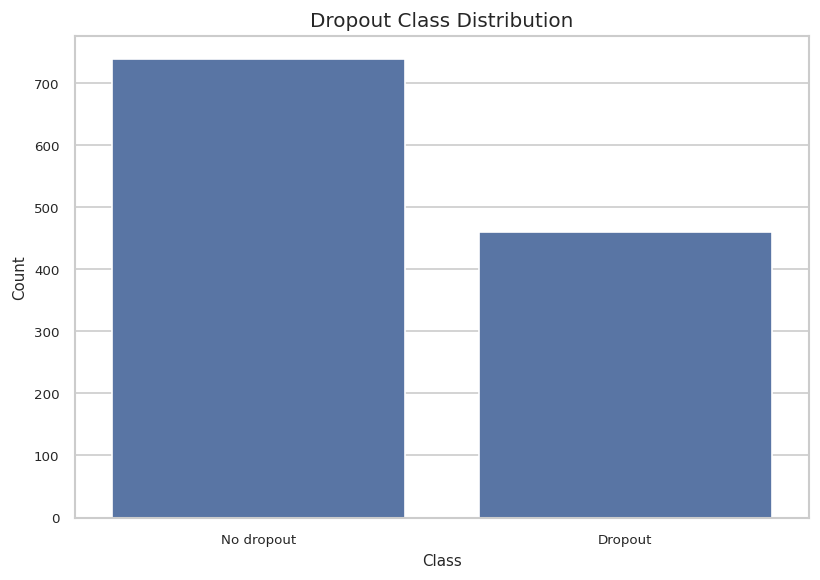

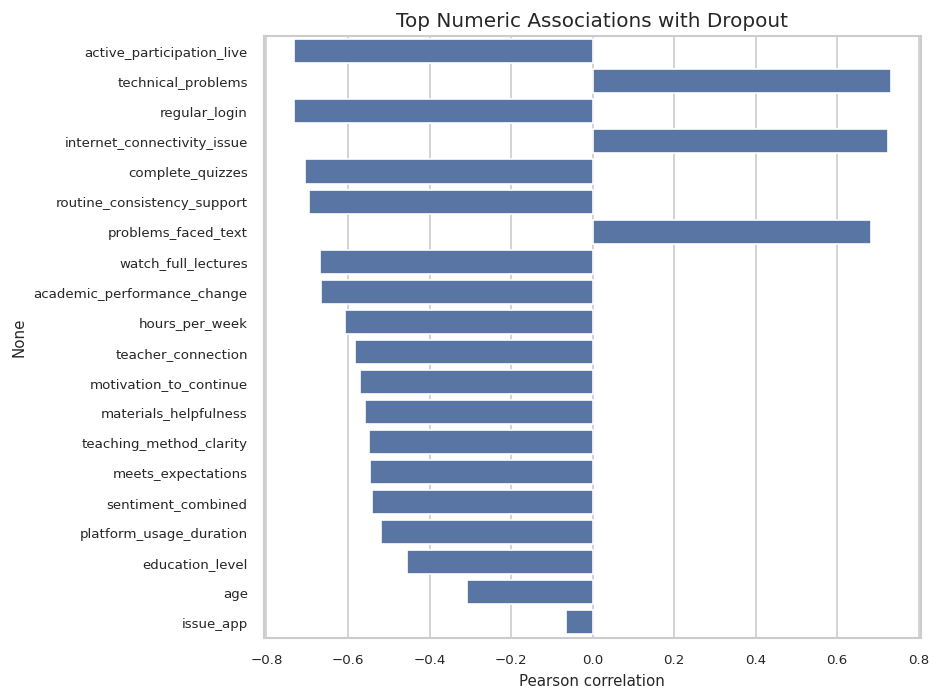

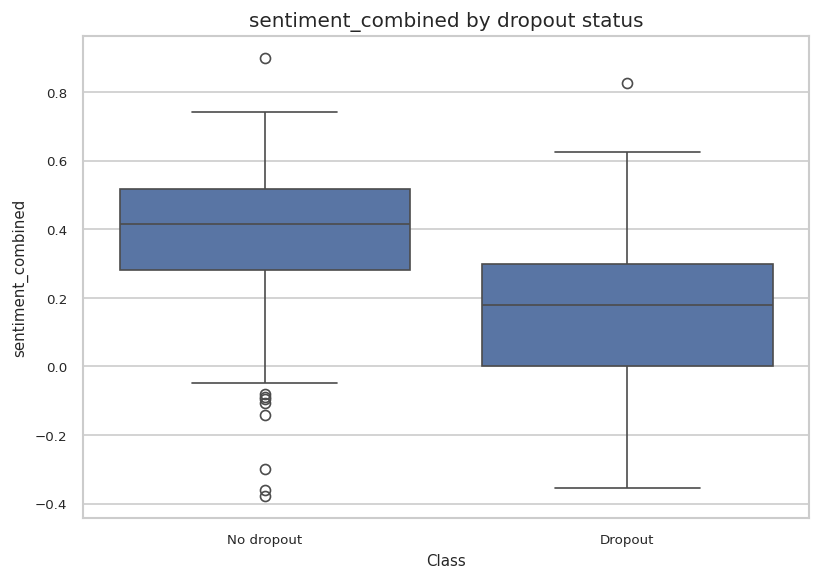

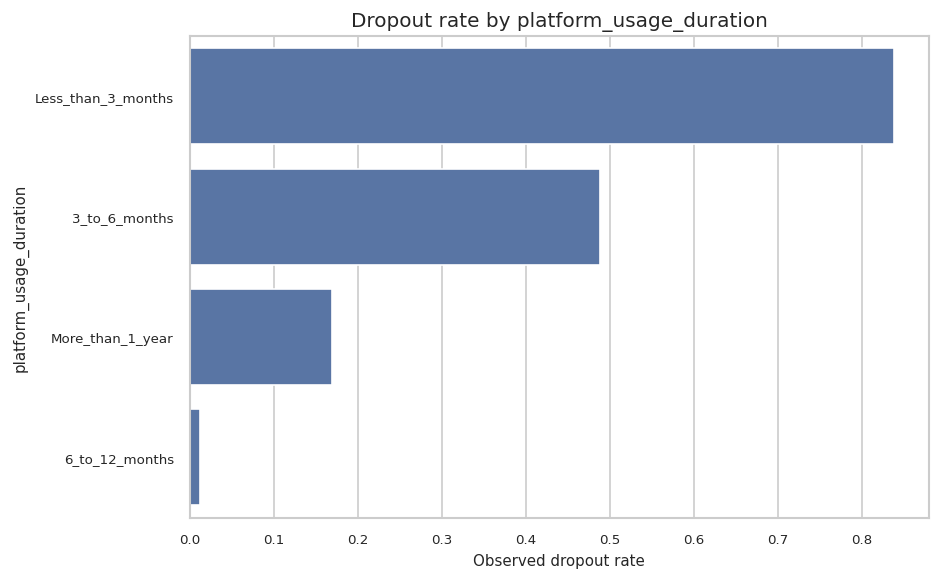

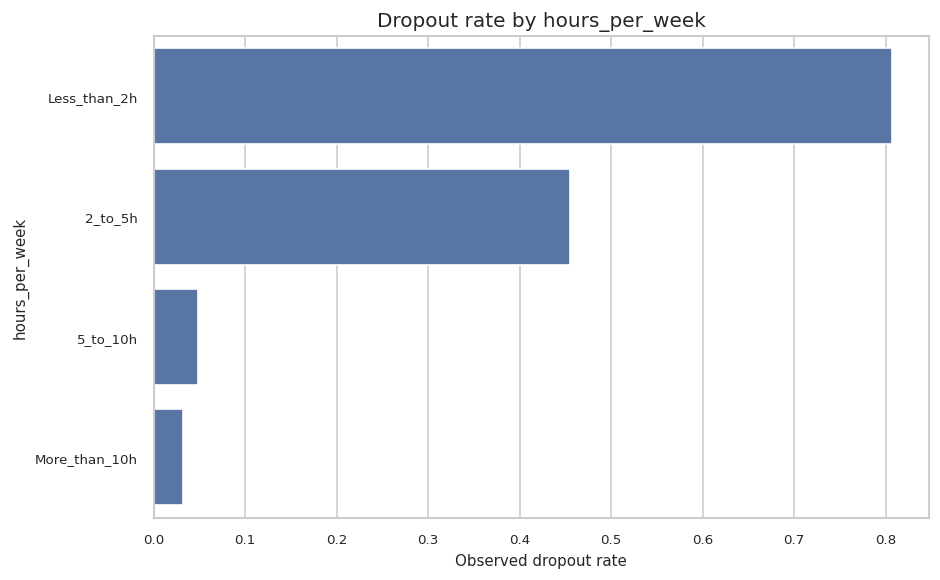

EDA outputs saved under: thesis_results/03_eda


In [ ]:
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "axes.titlesize": 12,
                     "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8})
y_lab = y.map({0: "No dropout", 1: "Dropout"})

# Target distribution (Figure 3.2)
fig, ax = plt.subplots(figsize=(7, 5))
sns.countplot(x=y_lab, order=["No dropout", "Dropout"], ax=ax)
ax.set_title("Dropout Class Distribution"); ax.set_xlabel("Class"); ax.set_ylabel("Count")
fig.tight_layout(); fig.savefig(BASE/"03_eda"/"01_target_distribution.png", bbox_inches="tight"); plt.show()

# Numeric descriptive statistics + Pearson correlation with target (Figure 3.3)
num_all = X_raw[numeric_cols]
num_all.describe().T.to_csv(BASE/"03_eda"/"numeric_descriptive_statistics.csv")
corr = pd.concat([num_all.reset_index(drop=True), y.reset_index(drop=True).rename("target")], axis=1)\
         .corr(numeric_only=True)["target"].drop("target").dropna().sort_values(key=np.abs, ascending=False)
corr.to_csv(BASE/"03_eda"/"pearson_correlation_with_target.csv")
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=corr.head(20).values, y=corr.head(20).index, ax=ax)
ax.set_title("Top Numeric Associations with Dropout"); ax.set_xlabel("Pearson correlation")
fig.tight_layout(); fig.savefig(BASE/"03_eda"/"02_top_numeric_correlations.png", bbox_inches="tight"); plt.show()

# Sentiment distributions by dropout status
for c in ACTIVE_SENTIMENT_COLS:
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.boxplot(x=y_lab, y=X_raw[c], order=["No dropout", "Dropout"], ax=ax)
    ax.set_title(f"{c} by dropout status"); ax.set_xlabel("Class"); ax.set_ylabel(c)
    fig.tight_layout(); fig.savefig(BASE/"03_eda"/f"{c}_by_dropout.png", bbox_inches="tight"); plt.show()

# Numeric feature distributions by dropout (Figures 3.6-3.13)
for c in numeric_cols:
    if X_raw[c].dropna().nunique() < 2:
        continue
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.histplot(data=pd.DataFrame({c: X_raw[c], "Dropout": y_lab}), x=c, hue="Dropout",
                 kde=X_raw[c].nunique() > 5, element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(f"{c} by dropout status")
    fig.tight_layout(); fig.savefig(BASE/"03_eda"/f"dist_{c}.png", dpi=250, bbox_inches="tight"); plt.close(fig)

# Observed dropout rate for every categorical question (Figures 3.4, 3.5 and others)
for c in CATEGORICAL_QUESTIONS:
    tmp = pd.DataFrame({c: X_all[c].astype(str), "target": y.values})
    rates = tmp.groupby(c)["target"].agg(["mean", "count"]).sort_values("mean", ascending=False)
    rates.to_csv(BASE/"03_eda"/f"categorical_{c}_dropout_rates.csv")
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.barplot(x=rates["mean"].values, y=rates.index, ax=ax)
    ax.set_title(f"Dropout rate by {c}"); ax.set_xlabel("Observed dropout rate")
    fig.tight_layout(); fig.savefig(BASE/"03_eda"/f"categorical_{c}_dropout_rate.png", bbox_inches="tight")
    if c in ("platform_usage_duration", "hours_per_week"):
        plt.show()
    plt.close(fig)

print("EDA outputs saved under:", BASE/"03_eda")

**EDA review.** The target plot should reflect the original class counts. The remaining figures and CSV summaries provide descriptive context for the structured inputs. Because several categorical responses are represented by fixed integer codes in this run, correlations involving those code columns should be interpreted cautiously; the numerical spacing between category labels is not necessarily substantive.

## 7. Mutual-information feature selection

Mutual information ranks the encoded predictors by their association with the binary target. The top-20 subset is derived from the training partition and then applied unchanged to the test matrix. The all-features condition retains the complete 26-column representation, while the reduced condition uses the 20 highest-ranked predictors.

Top 20 features (of 26):
 1. problems_faced_text                           0.436454
 2. sentiment_combined                            0.428093
 3. active_participation_live                     0.385544
 4. complete_quizzes                              0.373582
 5. technical_problems                            0.350834
 6. internet_connectivity_issue                   0.344761
 7. regular_login                                 0.335941
 8. routine_consistency_support                   0.333356
 9. academic_performance_change                   0.305373
10. age                                           0.291604
11. watch_full_lectures                           0.291542
12. hours_per_week                                0.249244
13. motivation_to_continue                        0.216649
14. platform_usage_duration                       0.211298
15. teacher_connection                            0.211029
16. meets_expectations                            0.202671
17. materials_helpfulness      

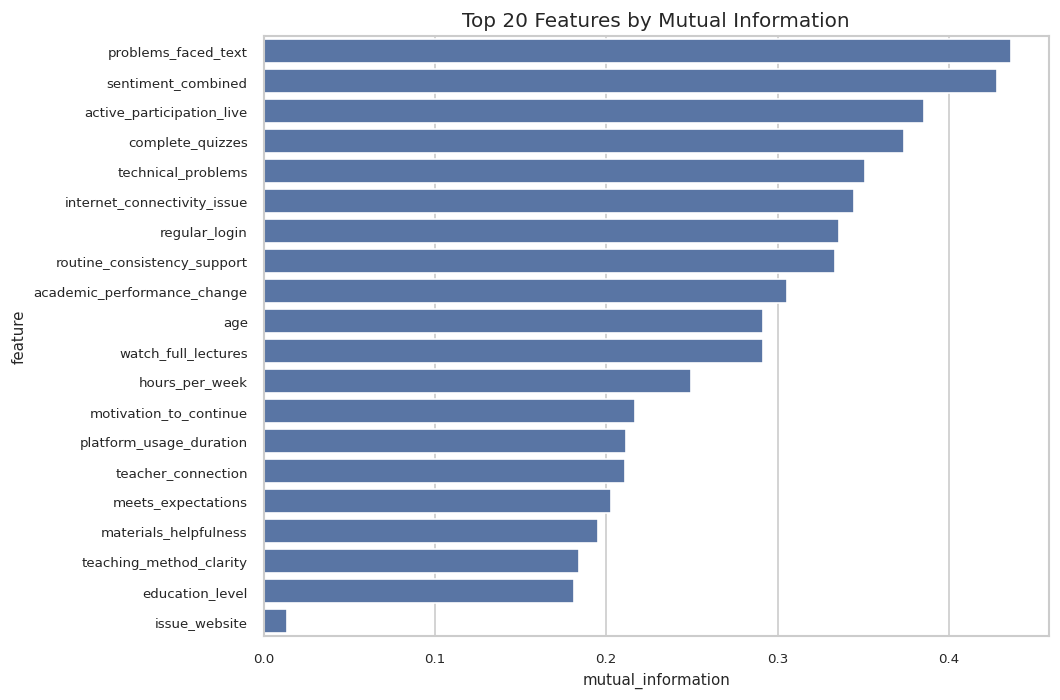

In [ ]:
k = min(20, Xtr.shape[1])
mi = mutual_info_classif(Xtr, y_train, random_state=RANDOM_STATE)
mi_table = pd.DataFrame({"feature": Xtr.columns, "mutual_information": mi})\
             .sort_values("mutual_information", ascending=False).reset_index(drop=True)
mi_table.to_csv(BASE/"04_feature_selection"/"mutual_information_all_features.csv", index=False)

top20_features = mi_table.head(k)["feature"].tolist()
Xtr20, Xte20 = Xtr[top20_features].copy(), Xte[top20_features].copy()
with open(BASE/"04_feature_selection"/"top20_features.json", "w", encoding="utf-8") as f:
    json.dump(top20_features, f, indent=2)

print(f"Top {k} features (of {Xtr.shape[1]}):")
for i, (f_, s_) in enumerate(zip(mi_table.head(k)["feature"], mi_table.head(k)["mutual_information"]), 1):
    print(f"{i:2d}. {f_:45s} {s_:.6f}")

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=mi_table.head(k), x="mutual_information", y="feature", ax=ax)
ax.set_title(f"Top {k} Features by Mutual Information")
fig.tight_layout(); fig.savefig(BASE/"04_feature_selection"/"top20_mutual_information.png", bbox_inches="tight"); plt.show()

**Feature-selection review.** Inspect the ranked table and figure, and confirm that exactly 20 feature names are retained. The test set is not used to compute the ranking. For transparency, note that the ranking is calculated once on the full 80% training partition before the five-fold model comparison; it is not recalculated independently inside each CV fold. This preserves the supplied experiment and reported scores, but means the CV estimate is not a fully nested estimate of the entire feature-selection procedure.

## 8. Classifier definitions

Ten classifier families are evaluated to cover tree ensembles, kernel and linear methods, multilayer perceptrons, and a one-dimensional convolutional network. The sklearn-based estimators and their hyperparameters are defined here. XGBoost and LightGBM are included when their packages are available; the ANN and CNN models are defined and evaluated in the TensorFlow section.

In [ ]:
try:
    from xgboost import XGBClassifier
except Exception as e:
    XGBClassifier = None
    print("XGBoost unavailable:", e)

try:
    from lightgbm import LGBMClassifier
except Exception as e:
    LGBMClassifier = None
    print("LightGBM unavailable:", e)

# ANN / CNN use TensorFlow/Keras. If it is missing they are skipped.
try:
    import tensorflow as tf
    from tensorflow.keras import Sequential
    from tensorflow.keras.layers import Dense, Dropout, Conv1D, GlobalMaxPooling1D, Input
    from tensorflow.keras.callbacks import EarlyStopping
    tf.random.set_seed(RANDOM_STATE)
    TF_AVAILABLE = True
except Exception as e:
    TF_AVAILABLE = False
    print("TensorFlow unavailable; ANN/CNN will be skipped:", e)

models = {
    "RF": RandomForestClassifier(n_estimators=500, class_weight="balanced",
                                 random_state=RANDOM_STATE, n_jobs=-1),
    "GradientBoosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "SVM": SVC(C=1.0, kernel="rbf", probability=True, class_weight="balanced",
               random_state=RANDOM_STATE),
    "MLP": MLPClassifier(hidden_layer_sizes=(128, 64), early_stopping=True,
                         max_iter=500, random_state=RANDOM_STATE),
    "LR": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "AdaBoost": AdaBoostClassifier(n_estimators=300, learning_rate=0.05, random_state=RANDOM_STATE),
}
if XGBClassifier is not None:
    models["XGBoost"] = XGBClassifier(
        n_estimators=400, max_depth=5, learning_rate=0.04, subsample=0.85, colsample_bytree=0.85,
        objective="binary:logistic", eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1)
if LGBMClassifier is not None:
    models["LGBM"] = LGBMClassifier(
        n_estimators=400, learning_rate=0.04, num_leaves=31, subsample=0.85, colsample_bytree=0.85,
        class_weight="balanced", random_state=RANDOM_STATE, verbosity=-1, n_jobs=-1)

print("Classical models:", list(models))

Classical models: ['RF', 'GradientBoosting', 'SVM', 'MLP', 'LR', 'AdaBoost', 'XGBoost', 'LGBM']


**Model availability check.** Review the printed list of classical models. If XGBoost or LightGBM is unavailable, the notebook reports that dependency and continues with the installed estimators. The classifier hyperparameters, seeds, and architecture settings from the supplied notebook have been retained.

## 9. Five-fold stratified evaluation and metric functions

This section defines the common evaluation protocol and metric calculations. Each training partition is divided into five stratified folds. For sklearn estimators, SMOTE is applied only to the current fold's training subset; the validation fold remains at its original class distribution. Out-of-fold probabilities are assembled for the training partition, after which a final model is fitted on the complete training partition (with training-only SMOTE) and evaluated on the held-out test set.

The reported measures are accuracy, balanced accuracy, precision, recall, F1-score, ROC-AUC, and average precision (PR-AUC). Threshold-dependent measures use the existing probability threshold of 0.5.

In [ ]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
METRIC_NAMES = ["accuracy", "balanced_accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]

def metric_row(y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, prob),
        "pr_auc": average_precision_score(y_true, prob),
    }

def smote_resample(X_fit, y_fit):
    """SMOTE (Eq. 3.2) applied only to the current training partition."""
    if not SMOTE_ENABLED:
        return X_fit, y_fit
    sm = SMOTE(random_state=SMOTE_RANDOM_STATE,
               k_neighbors=min(SMOTE_K_NEIGHBORS, max(1, int(y_fit.value_counts().min()) - 1)))
    X_res, y_res = sm.fit_resample(X_fit, y_fit)
    return pd.DataFrame(X_res, columns=X_fit.columns), pd.Series(y_res, name=y_fit.name)

def evaluate_sklearn_model(name, model, Xtr_use, Xte_use, scenario):
    oof_prob = np.zeros(len(y_train), dtype=float)
    fold_rows = []
    for fold, (tr_idx, va_idx) in enumerate(cv.split(Xtr_use, y_train), 1):
        X_fit, y_fit = Xtr_use.iloc[tr_idx], y_train.iloc[tr_idx]
        X_val, y_val = Xtr_use.iloc[va_idx], y_train.iloc[va_idx]
        X_fit_sm, y_fit_sm = smote_resample(X_fit, y_fit)
        m = clone(model).fit(X_fit_sm, y_fit_sm)
        p = m.predict_proba(X_val)[:, 1]
        oof_prob[va_idx] = p
        r = metric_row(y_val, p)
        r.update({"fold": fold, "train_n_before_smote": len(X_fit), "train_n_after_smote": len(X_fit_sm)})
        fold_rows.append(r)

    fold_df = pd.DataFrame(fold_rows)
    cv_metrics = metric_row(y_train, oof_prob)

    X_final_sm, y_final_sm = smote_resample(Xtr_use, y_train)
    final_model = clone(model).fit(X_final_sm, y_final_sm)
    test_prob = final_model.predict_proba(Xte_use)[:, 1]
    test_metrics = metric_row(y_test, test_prob)

    row = {"scenario": scenario, "model": name, "n_features": Xtr_use.shape[1],
           "smote_enabled": SMOTE_ENABLED, "smote_train_size": len(X_final_sm)}
    row.update({f"cv_{k_}": v for k_, v in cv_metrics.items()})
    for k_ in METRIC_NAMES:
        row[f"cv_{k_}_mean"] = fold_df[k_].mean()
        row[f"cv_{k_}_std"] = fold_df[k_].std(ddof=1)
    row.update({f"test_{k_}": v for k_, v in test_metrics.items()})
    return row, final_model, oof_prob, test_prob, fold_df

SCENARIOS = [("ALL_FEATURES", Xtr, Xte), ("TOP20_FEATURES", Xtr20, Xte20)]
all_results, fitted_models, predictions = [], {}, {}

**Protocol boundary to note.** The preprocessing object in Section 5 and the mutual-information ranking in Section 7 are each fitted once on the full 80% training partition before the five CV folds are formed. SMOTE is fold-specific, as implemented here, but imputation/scaling and top-20 feature selection are not refitted within every CV fold. The independent held-out test partition is not used for preprocessing, feature ranking, model selection, or ensemble selection. This distinction should be kept explicit when describing the validation design.

## 10. Classical-model benchmarking across both feature scenarios

The evaluation function is now applied to every available classical estimator under both `ALL_FEATURES` and `TOP20_FEATURES`. Fold-level metrics are saved separately, and the combined model table is written to the cross-validation results directory. Out-of-fold and held-out probability vectors are retained for downstream comparison, plotting, and ensemble evaluation.

In [ ]:
# Classical models: both feature scenarios. SMOTE is inside each CV training fold.
for scenario, Xtr_use, Xte_use in SCENARIOS:
    print("\n" + "=" * 80)
    print(f"{scenario}  ({Xtr_use.shape[1]} features)")
    print("=" * 80)
    for name, model in models.items():
        print("Running", name, "...")
        row, fitted, oof, testp, fold_df = evaluate_sklearn_model(name, model, Xtr_use, Xte_use, scenario)
        all_results.append(row)
        fitted_models[(scenario, name)] = fitted
        predictions[(scenario, name)] = {"oof": oof, "test": testp}
        fold_df.to_csv(BASE/"05_cv_results"/f"{scenario}_{name}_fold_metrics.csv", index=False)

results_df = pd.DataFrame(all_results)
results_df.to_csv(BASE/"05_cv_results"/"all_classical_model_results.csv", index=False)
results_df


ALL_FEATURES  (26 features)
Running RF ...
Running GradientBoosting ...
Running SVM ...
Running MLP ...
Running LR ...
Running AdaBoost ...
Running XGBoost ...
Running LGBM ...

TOP20_FEATURES  (20 features)
Running RF ...
Running GradientBoosting ...
Running SVM ...
Running MLP ...
Running LR ...
Running AdaBoost ...
Running XGBoost ...
Running LGBM ...


,scenario,model,n_features,smote_enabled,smote_train_size,cv_accuracy,cv_balanced_accuracy,cv_precision,cv_recall,cv_f1,...,cv_roc_auc_std,cv_pr_auc_mean,cv_pr_auc_std,test_accuracy,test_balanced_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_pr_auc
0,ALL_FEATURES,RF,26,True,1182,0.936458,0.930578,0.927778,0.905149,0.916324,...,0.005899,0.981341,0.007933,0.941667,0.940364,0.914894,0.934783,0.924731,0.985789,0.978869
1,ALL_FEATURES,GradientBoosting,26,True,1182,0.931250,0.926857,0.912807,0.907859,0.910326,...,0.012264,0.977174,0.011647,0.883333,0.880729,0.833333,0.869565,0.851064,0.975250,0.962466
2,ALL_FEATURES,SVM,26,True,1182,0.936458,0.932614,0.918478,0.915989,0.917232,...,0.009939,0.969595,0.015965,0.916667,0.915981,0.875000,0.913043,0.893617,0.972459,0.955670
3,ALL_FEATURES,MLP,26,True,1182,0.929167,0.925674,0.905660,0.910569,0.908108,...,0.011029,0.972173,0.010228,0.895833,0.897033,0.838384,0.902174,0.869110,0.972679,0.965079
4,ALL_FEATURES,LR,26,True,1182,0.921875,0.918225,0.895161,0.902439,0.898785,...,0.018699,0.969903,0.012394,0.887500,0.884107,0.842105,0.869565,0.855615,0.972826,0.962450
5,ALL_FEATURES,AdaBoost,26,True,1182,0.919792,0.910934,0.914773,0.872629,0.893204,...,0.006822,0.976170,0.007889,0.887500,0.879994,0.857143,0.847826,0.852459,0.975764,0.964984
6,ALL_FEATURES,XGBoost,26,True,1182,0.929167,0.922620,0.919220,0.894309,0.906593,...,0.006624,0.979372,0.008510,0.929167,0.930229,0.886598,0.934783,0.910053,0.984504,0.977018
7,ALL_FEATURES,LGBM,26,True,1182,0.936458,0.932105,0.920765,0.913279,0.917007,...,0.004893,0.981488,0.006990,0.929167,0.928173,0.894737,0.923913,0.909091,0.983402,0.975297
8,TOP20_FEATURES,RF,20,True,1182,0.936458,0.931596,0.923077,0.910569,0.916780,...,0.006446,0.981517,0.008494,0.937500,0.939042,0.896907,0.945652,0.920635,0.985752,0.978958
9,TOP20_FEATURES,GradientBoosting,20,True,1182,0.927083,0.921946,0.909589,0.899729,0.904632,...,0.010041,0.979025,0.010056,0.891667,0.889542,0.843750,0.880435,0.861702,0.978334,0.967472


**Benchmarking output.** The cell produces the classical-model results for both feature scenarios and saves per-fold metric files. The saved predictions are reused in later cells, so run this cell before the comparison, curve, confusion-matrix, and ensemble sections. No held-out test result is used to select a model for the CV-based ensemble.

## 11. ANN and 1-D CNN evaluation

The neural architectures follow the supplied design: the ANN uses dense layers with dropout, while the CNN applies one-dimensional convolutional layers to the feature vector. A fresh model is created for each fold. Early stopping monitors validation loss, and SMOTE is restricted to the fold's training subset. When TensorFlow is unavailable, these models are skipped and the remaining workflow continues.

In [ ]:
def build_ann(input_dim):
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(128, activation="relu"), Dropout(0.30),
        Dense(64, activation="relu"), Dropout(0.20),
        Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model

def build_cnn(input_dim):
    model = Sequential([
        Input(shape=(input_dim, 1)),
        Conv1D(32, 3, activation="relu", padding="same"),
        Conv1D(16, 3, activation="relu", padding="same"),
        GlobalMaxPooling1D(),
        Dense(32, activation="relu"), Dropout(0.25),
        Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model

def _smote_np(X_, y_):
    if not SMOTE_ENABLED:
        return X_, y_
    sm = SMOTE(random_state=SMOTE_RANDOM_STATE,
               k_neighbors=min(SMOTE_K_NEIGHBORS, max(1, int(np.bincount(y_.astype(int)).min()) - 1)))
    return sm.fit_resample(X_, y_)

def keras_cv_evaluate(model_type, Xtr_use, Xte_use, scenario):
    Xn = Xtr_use.values.astype("float32")
    Xt = Xte_use.values.astype("float32")
    y_np = y_train.values.astype("float32")
    build = build_ann if model_type == "ANN" else build_cnn
    reshape = (lambda a: a) if model_type == "ANN" else (lambda a: a[..., None])

    oof = np.zeros(len(y_np), dtype=float)
    fold_rows = []
    for fold, (tr_idx, va_idx) in enumerate(cv.split(Xn, y_np), 1):
        X_fit, y_fit = _smote_np(Xn[tr_idx], y_np[tr_idx])       # SMOTE on the training fold only
        X_val, y_val = Xn[va_idx], y_np[va_idx]
        model = build(Xn.shape[1])
        es = EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
        model.fit(reshape(X_fit), y_fit, validation_data=(reshape(X_val), y_val),
                  epochs=150, batch_size=32, verbose=0, callbacks=[es])
        p = model.predict(reshape(X_val), verbose=0).ravel()
        oof[va_idx] = p
        r = metric_row(y_val, p); r["fold"] = fold
        fold_rows.append(r)

    fold_df = pd.DataFrame(fold_rows)
    cv_metrics = metric_row(y_train, oof)

    X_final, y_final = _smote_np(Xn, y_np)                      # final fit: training partition only
    final_model = build(Xn.shape[1])
    final_model.fit(reshape(X_final), y_final, epochs=150, batch_size=32, verbose=0, validation_split=0.15,
                    callbacks=[EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)])
    testp = final_model.predict(reshape(Xt), verbose=0).ravel()
    test_metrics = metric_row(y_test, testp)

    row = {"scenario": scenario, "model": model_type, "n_features": Xn.shape[1]}
    row.update({f"cv_{k_}": v for k_, v in cv_metrics.items()})
    for k_ in METRIC_NAMES:
        row[f"cv_{k_}_mean"] = fold_df[k_].mean()
        row[f"cv_{k_}_std"] = fold_df[k_].std(ddof=1)
    row.update({f"test_{k_}": v for k_, v in test_metrics.items()})
    return row, final_model, oof, testp, fold_df

if TF_AVAILABLE:
    for scenario, Xtr_use, Xte_use in SCENARIOS:
        for model_name in ["ANN", "CNN"]:
            print("Running", scenario, model_name)
            row, fitted, oof, testp, fold_df = keras_cv_evaluate(model_name, Xtr_use, Xte_use, scenario)
            all_results.append(row)
            fitted_models[(scenario, model_name)] = fitted
            predictions[(scenario, model_name)] = {"oof": oof, "test": testp}
            fold_df.to_csv(BASE/"05_cv_results"/f"{scenario}_{model_name}_fold_metrics.csv", index=False)

results_df = pd.DataFrame(all_results)
results_df.to_csv(BASE/"05_cv_results"/"all_model_results.csv", index=False)
results_df.sort_values(["scenario", "cv_f1"], ascending=[True, False])

Running ALL_FEATURES ANN
Running ALL_FEATURES CNN
Running TOP20_FEATURES ANN
Running TOP20_FEATURES CNN


,scenario,model,n_features,smote_enabled,smote_train_size,cv_accuracy,cv_balanced_accuracy,cv_precision,cv_recall,cv_f1,...,cv_roc_auc_std,cv_pr_auc_mean,cv_pr_auc_std,test_accuracy,test_balanced_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_pr_auc
2,ALL_FEATURES,SVM,26,True,1182.0,0.936458,0.932614,0.918478,0.915989,0.917232,...,0.009939,0.969595,0.015965,0.916667,0.915981,0.875000,0.913043,0.893617,0.972459,0.955670
7,ALL_FEATURES,LGBM,26,True,1182.0,0.936458,0.932105,0.920765,0.913279,0.917007,...,0.004893,0.981488,0.006990,0.929167,0.928173,0.894737,0.923913,0.909091,0.983402,0.975297
0,ALL_FEATURES,RF,26,True,1182.0,0.936458,0.930578,0.927778,0.905149,0.916324,...,0.005899,0.981341,0.007933,0.941667,0.940364,0.914894,0.934783,0.924731,0.985789,0.978869
1,ALL_FEATURES,GradientBoosting,26,True,1182.0,0.931250,0.926857,0.912807,0.907859,0.910326,...,0.012264,0.977174,0.011647,0.883333,0.880729,0.833333,0.869565,0.851064,0.975250,0.962466
16,ALL_FEATURES,ANN,26,NaN,NaN,0.930208,0.926520,0.908108,0.910569,0.909337,...,0.012370,0.976389,0.009895,0.908333,0.905112,0.872340,0.891304,0.881720,0.981492,0.974024
3,ALL_FEATURES,MLP,26,True,1182.0,0.929167,0.925674,0.905660,0.910569,0.908108,...,0.011029,0.972173,0.010228,0.895833,0.897033,0.838384,0.902174,0.869110,0.972679,0.965079
6,ALL_FEATURES,XGBoost,26,True,1182.0,0.929167,0.922620,0.919220,0.894309,0.906593,...,0.006624,0.979372,0.008510,0.929167,0.930229,0.886598,0.934783,0.910053,0.984504,0.977018
4,ALL_FEATURES,LR,26,True,1182.0,0.921875,0.918225,0.895161,0.902439,0.898785,...,0.018699,0.969903,0.012394,0.887500,0.884107,0.842105,0.869565,0.855615,0.972826,0.962450
5,ALL_FEATURES,AdaBoost,26,True,1182.0,0.919792,0.910934,0.914773,0.872629,0.893204,...,0.006822,0.976170,0.007889,0.887500,0.879994,0.857143,0.847826,0.852459,0.975764,0.964984
17,ALL_FEATURES,CNN,26,NaN,NaN,0.906250,0.900953,0.878049,0.878049,0.878049,...,0.009975,0.948466,0.022819,0.916667,0.905699,0.918605,0.858696,0.887640,0.966657,0.955256


**Neural-model output.** When TensorFlow is installed, the ANN and CNN results are appended to the same results structure as the classical estimators. Check that both models appear in `results_df` when the optional dependency is available. Their layer sizes, dropout rates, optimizer, epoch limit, batch size, and early-stopping patience have not been modified.

## 12. Consolidated model comparison

The comparison table reports mean and standard deviation for cross-validation accuracy, alongside the other fold-mean metrics and the independent test metrics. Models are sorted within each feature scenario using mean CV F1-score, with CV ROC-AUC as a secondary ordering criterion. This keeps the model-selection rule tied to development data while leaving the held-out test results as final assessment only.

In [ ]:
display_cols = [
    "scenario", "model", "n_features",
    "cv_accuracy_mean", "cv_accuracy_std", "cv_balanced_accuracy_mean", "cv_precision_mean",
    "cv_recall_mean", "cv_f1_mean", "cv_roc_auc_mean", "cv_pr_auc_mean",
    "test_accuracy", "test_balanced_accuracy", "test_precision", "test_recall",
    "test_f1", "test_roc_auc", "test_pr_auc",
]
comparison = results_df[display_cols].sort_values(
    ["scenario", "cv_f1_mean", "cv_roc_auc_mean"], ascending=[True, False, False])
comparison.to_csv(BASE/"13_summary"/"complete_model_comparison.csv", index=False)
display(comparison)

for sc in ["ALL_FEATURES", "TOP20_FEATURES"]:
    print(f"\nTop 3 models — {sc}")
    display(comparison[comparison["scenario"] == sc][
        ["model", "cv_accuracy_mean", "test_accuracy", "cv_f1_mean", "test_f1", "cv_recall_mean", "test_recall"]].head(3))

,scenario,model,n_features,cv_accuracy_mean,cv_accuracy_std,cv_balanced_accuracy_mean,cv_precision_mean,cv_recall_mean,cv_f1_mean,cv_roc_auc_mean,cv_pr_auc_mean,test_accuracy,test_balanced_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_pr_auc
2,ALL_FEATURES,SVM,26,0.936458,0.011291,0.932700,0.919522,0.916105,0.917065,0.980142,0.969595,0.916667,0.915981,0.875000,0.913043,0.893617,0.972459,0.955670
7,ALL_FEATURES,LGBM,26,0.936458,0.019969,0.932219,0.921305,0.913476,0.916278,0.987415,0.981488,0.929167,0.928173,0.894737,0.923913,0.909091,0.983402,0.975297
0,ALL_FEATURES,RF,26,0.936458,0.019278,0.930659,0.928727,0.905257,0.915993,0.987240,0.981341,0.941667,0.940364,0.914894,0.934783,0.924731,0.985789,0.978869
1,ALL_FEATURES,GradientBoosting,26,0.931250,0.011877,0.926925,0.913596,0.907960,0.910176,0.981641,0.977174,0.883333,0.880729,0.833333,0.869565,0.851064,0.975250,0.962466
16,ALL_FEATURES,ANN,26,0.930208,0.008715,0.926633,0.909488,0.910737,0.909074,0.981480,0.976389,0.908333,0.905112,0.872340,0.891304,0.881720,0.981492,0.974024
3,ALL_FEATURES,MLP,26,0.929167,0.009461,0.925771,0.907924,0.910737,0.907685,0.979373,0.972173,0.895833,0.897033,0.838384,0.902174,0.869110,0.972679,0.965079
6,ALL_FEATURES,XGBoost,26,0.929167,0.019695,0.922722,0.919704,0.894484,0.906217,0.985719,0.979372,0.929167,0.930229,0.886598,0.934783,0.910053,0.984504,0.977018
4,ALL_FEATURES,LR,26,0.921875,0.003683,0.918330,0.896709,0.902592,0.898623,0.974423,0.969903,0.887500,0.884107,0.842105,0.869565,0.855615,0.972826,0.962450
5,ALL_FEATURES,AdaBoost,26,0.919792,0.014546,0.910986,0.915876,0.872677,0.893073,0.982737,0.976170,0.887500,0.879994,0.857143,0.847826,0.852459,0.975764,0.964984
17,ALL_FEATURES,CNN,26,0.906250,0.015185,0.900974,0.878691,0.878119,0.878237,0.965014,0.948466,0.916667,0.905699,0.918605,0.858696,0.887640,0.966657,0.955256



Top 3 models — ALL_FEATURES


,model,cv_accuracy_mean,test_accuracy,cv_f1_mean,test_f1,cv_recall_mean,test_recall
2,SVM,0.936458,0.916667,0.917065,0.893617,0.916105,0.913043
7,LGBM,0.936458,0.929167,0.916278,0.909091,0.913476,0.923913
0,RF,0.936458,0.941667,0.915993,0.924731,0.905257,0.934783



Top 3 models — TOP20_FEATURES


,model,cv_accuracy_mean,test_accuracy,cv_f1_mean,test_f1,cv_recall_mean,test_recall
10,SVM,0.937500,0.916667,0.917820,0.894737,0.913402,0.923913
8,RF,0.936458,0.937500,0.916382,0.920635,0.910700,0.945652
15,LGBM,0.931250,0.916667,0.909114,0.892473,0.899926,0.902174


**Headline results in the retained output snapshot.** In the all-features scenario, Random Forest reports 94.17% test accuracy, 94.04% balanced accuracy, 92.47% F1, 98.58% ROC-AUC, and 97.89% PR-AUC. In the top-20 scenario, Random Forest reports 93.75% test accuracy, 93.90% balanced accuracy, 92.06% F1, 98.58% ROC-AUC, and 97.90% PR-AUC. These are the principal results stated in the attached paper; the full table should be reviewed for all model-specific values.

## 13. Held-out confusion matrices and probability-ranking curves

Confusion matrices are generated at the fixed 0.5 probability threshold. ROC and precision–recall curves use the held-out predicted probabilities for each model and feature scenario. The chance line is shown on ROC curves, and the class prevalence is shown as a reference line on precision–recall plots. All figures are saved at publication-oriented resolution.

Confusion matrices saved.


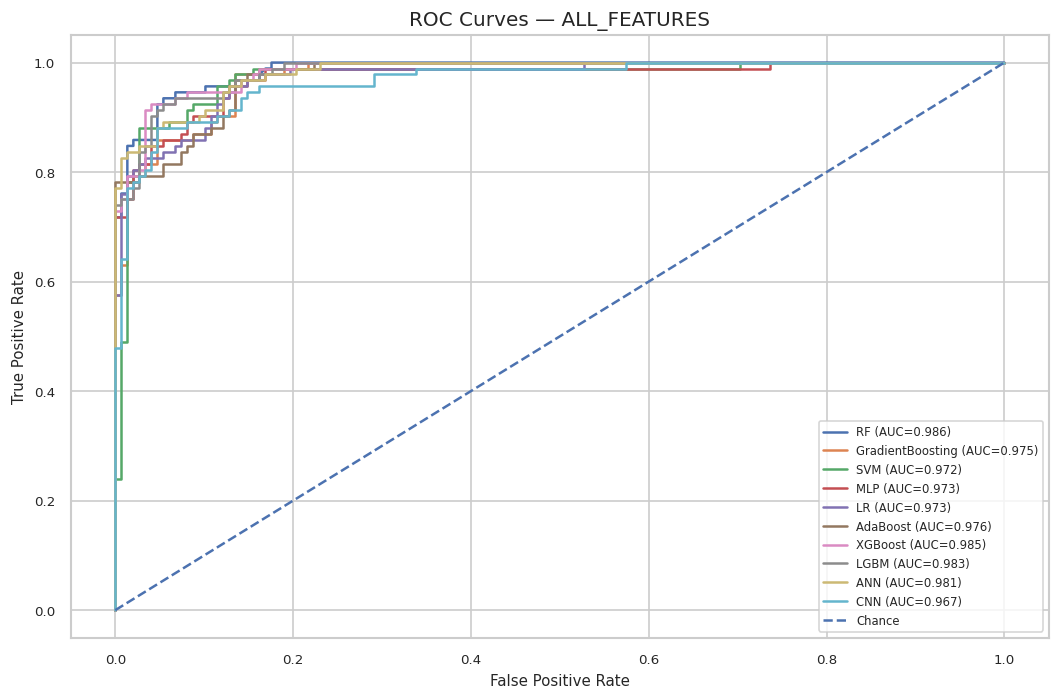

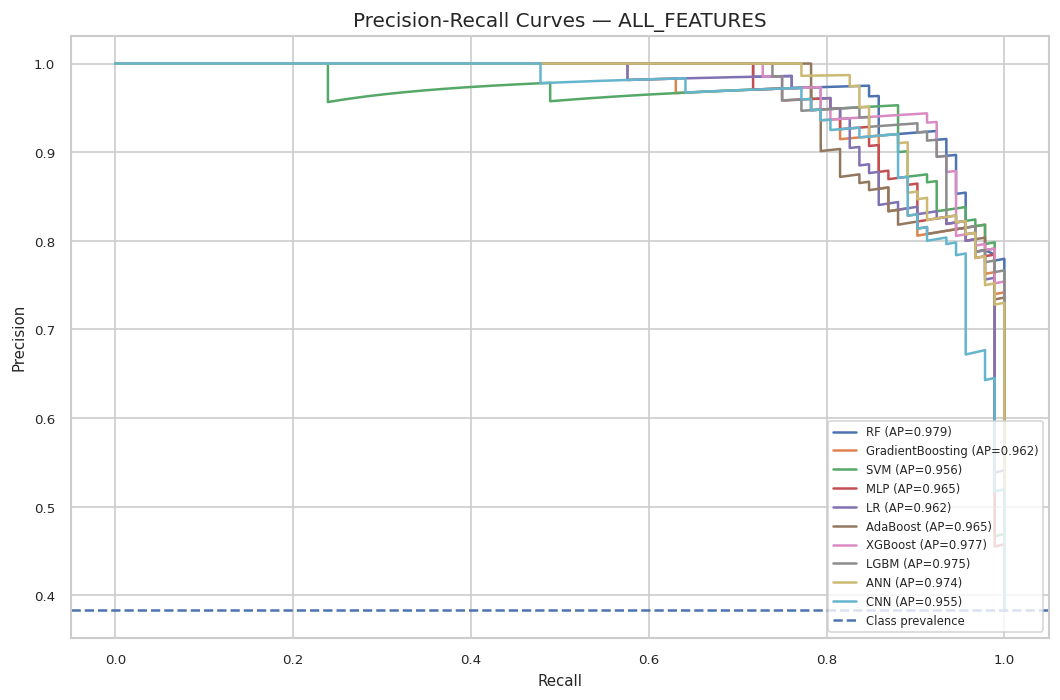

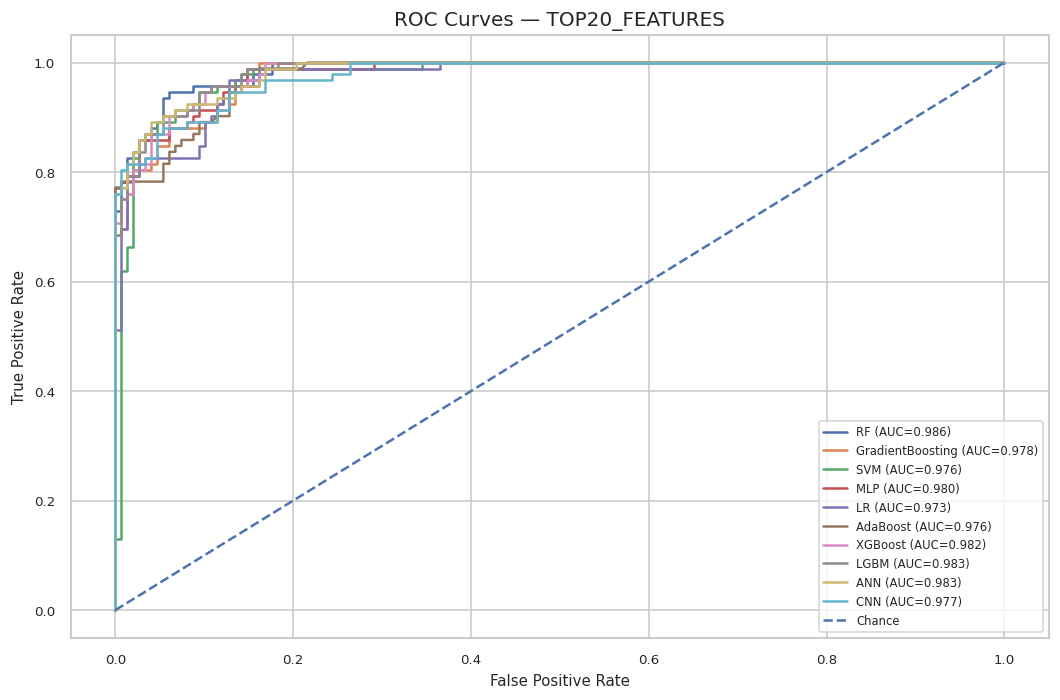

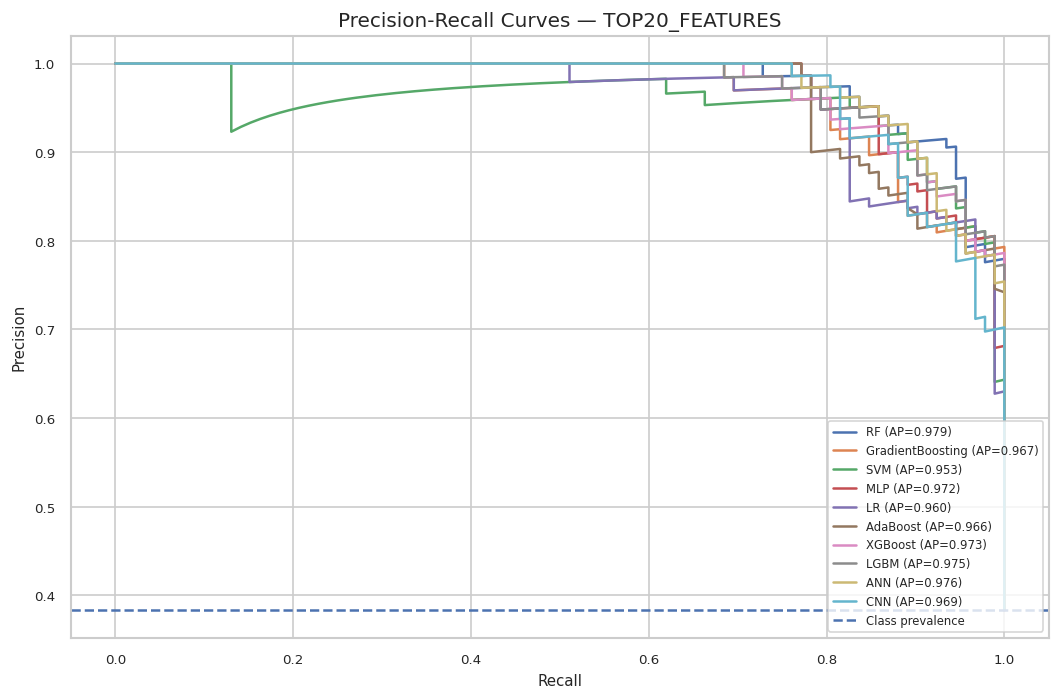

ROC and PR curves saved.


In [ ]:
for (scenario, model_name), pred in predictions.items():
    cm = confusion_matrix(y_test, (pred["test"] >= 0.5).astype(int))
    fig, ax = plt.subplots(figsize=(5.2, 4.2))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(scenario.replace("_", " ") + " — " + model_name, fontsize=11)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    fig.tight_layout(pad=1.0)
    fig.savefig(BASE/"07_confusion_matrices"/f"{scenario}_{model_name}.png", dpi=300)
    plt.close(fig)
print("Confusion matrices saved.")

for scenario in ["ALL_FEATURES", "TOP20_FEATURES"]:
    fig, ax = plt.subplots(figsize=(9, 6))
    for (sc, model_name), pred in predictions.items():
        if sc != scenario: continue
        fpr, tpr, _ = roc_curve(y_test, pred["test"])
        ax.plot(fpr, tpr, label=f"{model_name} (AUC={roc_auc_score(y_test, pred['test']):.3f})")
    ax.plot([0, 1], [0, 1], "--", label="Chance")
    ax.set_title(f"ROC Curves — {scenario}"); ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
    ax.legend(fontsize=7, loc="lower right", frameon=True)
    fig.tight_layout(); fig.savefig(BASE/"08_roc_curves"/f"{scenario}_ROC.png", dpi=300, bbox_inches="tight")
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 6))
    for (sc, model_name), pred in predictions.items():
        if sc != scenario: continue
        pr_, rc_, _ = precision_recall_curve(y_test, pred["test"])
        ax.plot(rc_, pr_, label=f"{model_name} (AP={average_precision_score(y_test, pred['test']):.3f})")
    ax.axhline(y_test.mean(), linestyle="--", label="Class prevalence")
    ax.set_title(f"Precision-Recall Curves — {scenario}"); ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
    ax.legend(fontsize=7, loc="lower right", frameon=True)
    fig.tight_layout(); fig.savefig(BASE/"09_pr_curves"/f"{scenario}_PR.png", dpi=300, bbox_inches="tight")
    plt.show()
print("ROC and PR curves saved.")

**Diagnostic review.** Compare false positives and false negatives across models rather than relying on accuracy alone. ROC-AUC and PR-AUC summarize ranking behaviour across thresholds, whereas the confusion matrices describe one fixed operating threshold. The figures are saved under `07_confusion_matrices/`, `08_roc_curves/`, and `09_pr_curves/`.

## 14. Top-three soft-voting ensembles

For each feature scenario, the three eligible models with the highest mean five-fold CV F1-score are selected. Their dropout probabilities are averaged to form the soft-voting prediction. Selection uses CV results only; the held-out test set is not used to choose ensemble members. Out-of-fold and held-out ensemble probabilities and the summary table are saved separately.

In [ ]:
ensemble_rows = []
for scenario in ["ALL_FEATURES", "TOP20_FEATURES"]:
    subset = results_df[(results_df.scenario == scenario) &
                        (~results_df.model.isin(["ANN", "CNN"]))]\
                .sort_values(["cv_f1_mean", "cv_roc_auc_mean"], ascending=False)
    top3 = subset.head(3)["model"].tolist()
    print(scenario, "top 3:", top3)

    oof_prob = np.column_stack([predictions[(scenario, m)]["oof"] for m in top3]).mean(axis=1)
    test_prob = np.column_stack([predictions[(scenario, m)]["test"] for m in top3]).mean(axis=1)

    row = {"scenario": scenario, "model": "Top3_SoftVoting"}
    row.update({f"cv_{k_}": v for k_, v in metric_row(y_train, oof_prob).items()})
    row.update({f"test_{k_}": v for k_, v in metric_row(y_test, test_prob).items()})
    row["ensemble_members"] = ", ".join(top3)
    ensemble_rows.append(row)

    pd.DataFrame({"y_train": y_train.values, "oof_probability": oof_prob}).to_csv(
        BASE/"11_ensembles"/f"{scenario}_ensemble_oof.csv", index=False)
    pd.DataFrame({"y_test": y_test.values, "test_probability": test_prob}).to_csv(
        BASE/"11_ensembles"/f"{scenario}_ensemble_test.csv", index=False)

ensemble_df = pd.DataFrame(ensemble_rows)
ensemble_df.to_csv(BASE/"11_ensembles"/"ensemble_results.csv", index=False)
display(ensemble_df)

ALL_FEATURES top 3: ['SVM', 'LGBM', 'RF']
TOP20_FEATURES top 3: ['SVM', 'RF', 'LGBM']


,scenario,model,cv_accuracy,cv_balanced_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,cv_pr_auc,test_accuracy,test_balanced_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_pr_auc,ensemble_members
0,ALL_FEATURES,Top3_SoftVoting,0.938542,0.933288,0.928177,0.910569,0.919289,0.987468,0.981655,0.933333,0.933608,0.895833,0.934783,0.914894,0.984724,0.976897,"SVM, LGBM, RF"
1,TOP20_FEATURES,Top3_SoftVoting,0.938542,0.933288,0.928177,0.910569,0.919289,0.988192,0.982578,0.925000,0.924794,0.885417,0.923913,0.904255,0.984430,0.976785,"SVM, RF, LGBM"


**Ensemble review.** The retained output selects SVM, LightGBM, and Random Forest for the all-features scenario, and SVM, Random Forest, and LightGBM for the top-20 scenario. Soft voting is treated as a comparison, not an assumed improvement: the ensemble does not exceed the strongest individual Random Forest on held-out F1 in either scenario.

## 15. SHAP-based model interpretation

TreeExplainer is applied to the best-CV-F1 eligible tree model in each feature scenario. The explanation uses the final model fitted on the training partition and a sample of held-out feature rows. Global beeswarm and bar plots summarize feature contributions; a waterfall plot explains one representative held-out prediction, and a dependence plot examines the highest-importance feature.

SHAP values describe the fitted model's associations and are not causal effects. Positive contributions move the model output toward the dropout class; negative contributions move it away.

SHAP completed: ALL_FEATURES LGBM
SHAP completed: TOP20_FEATURES RF

### SHAP plots — LGBM — ALL_FEATURES
beeswarm


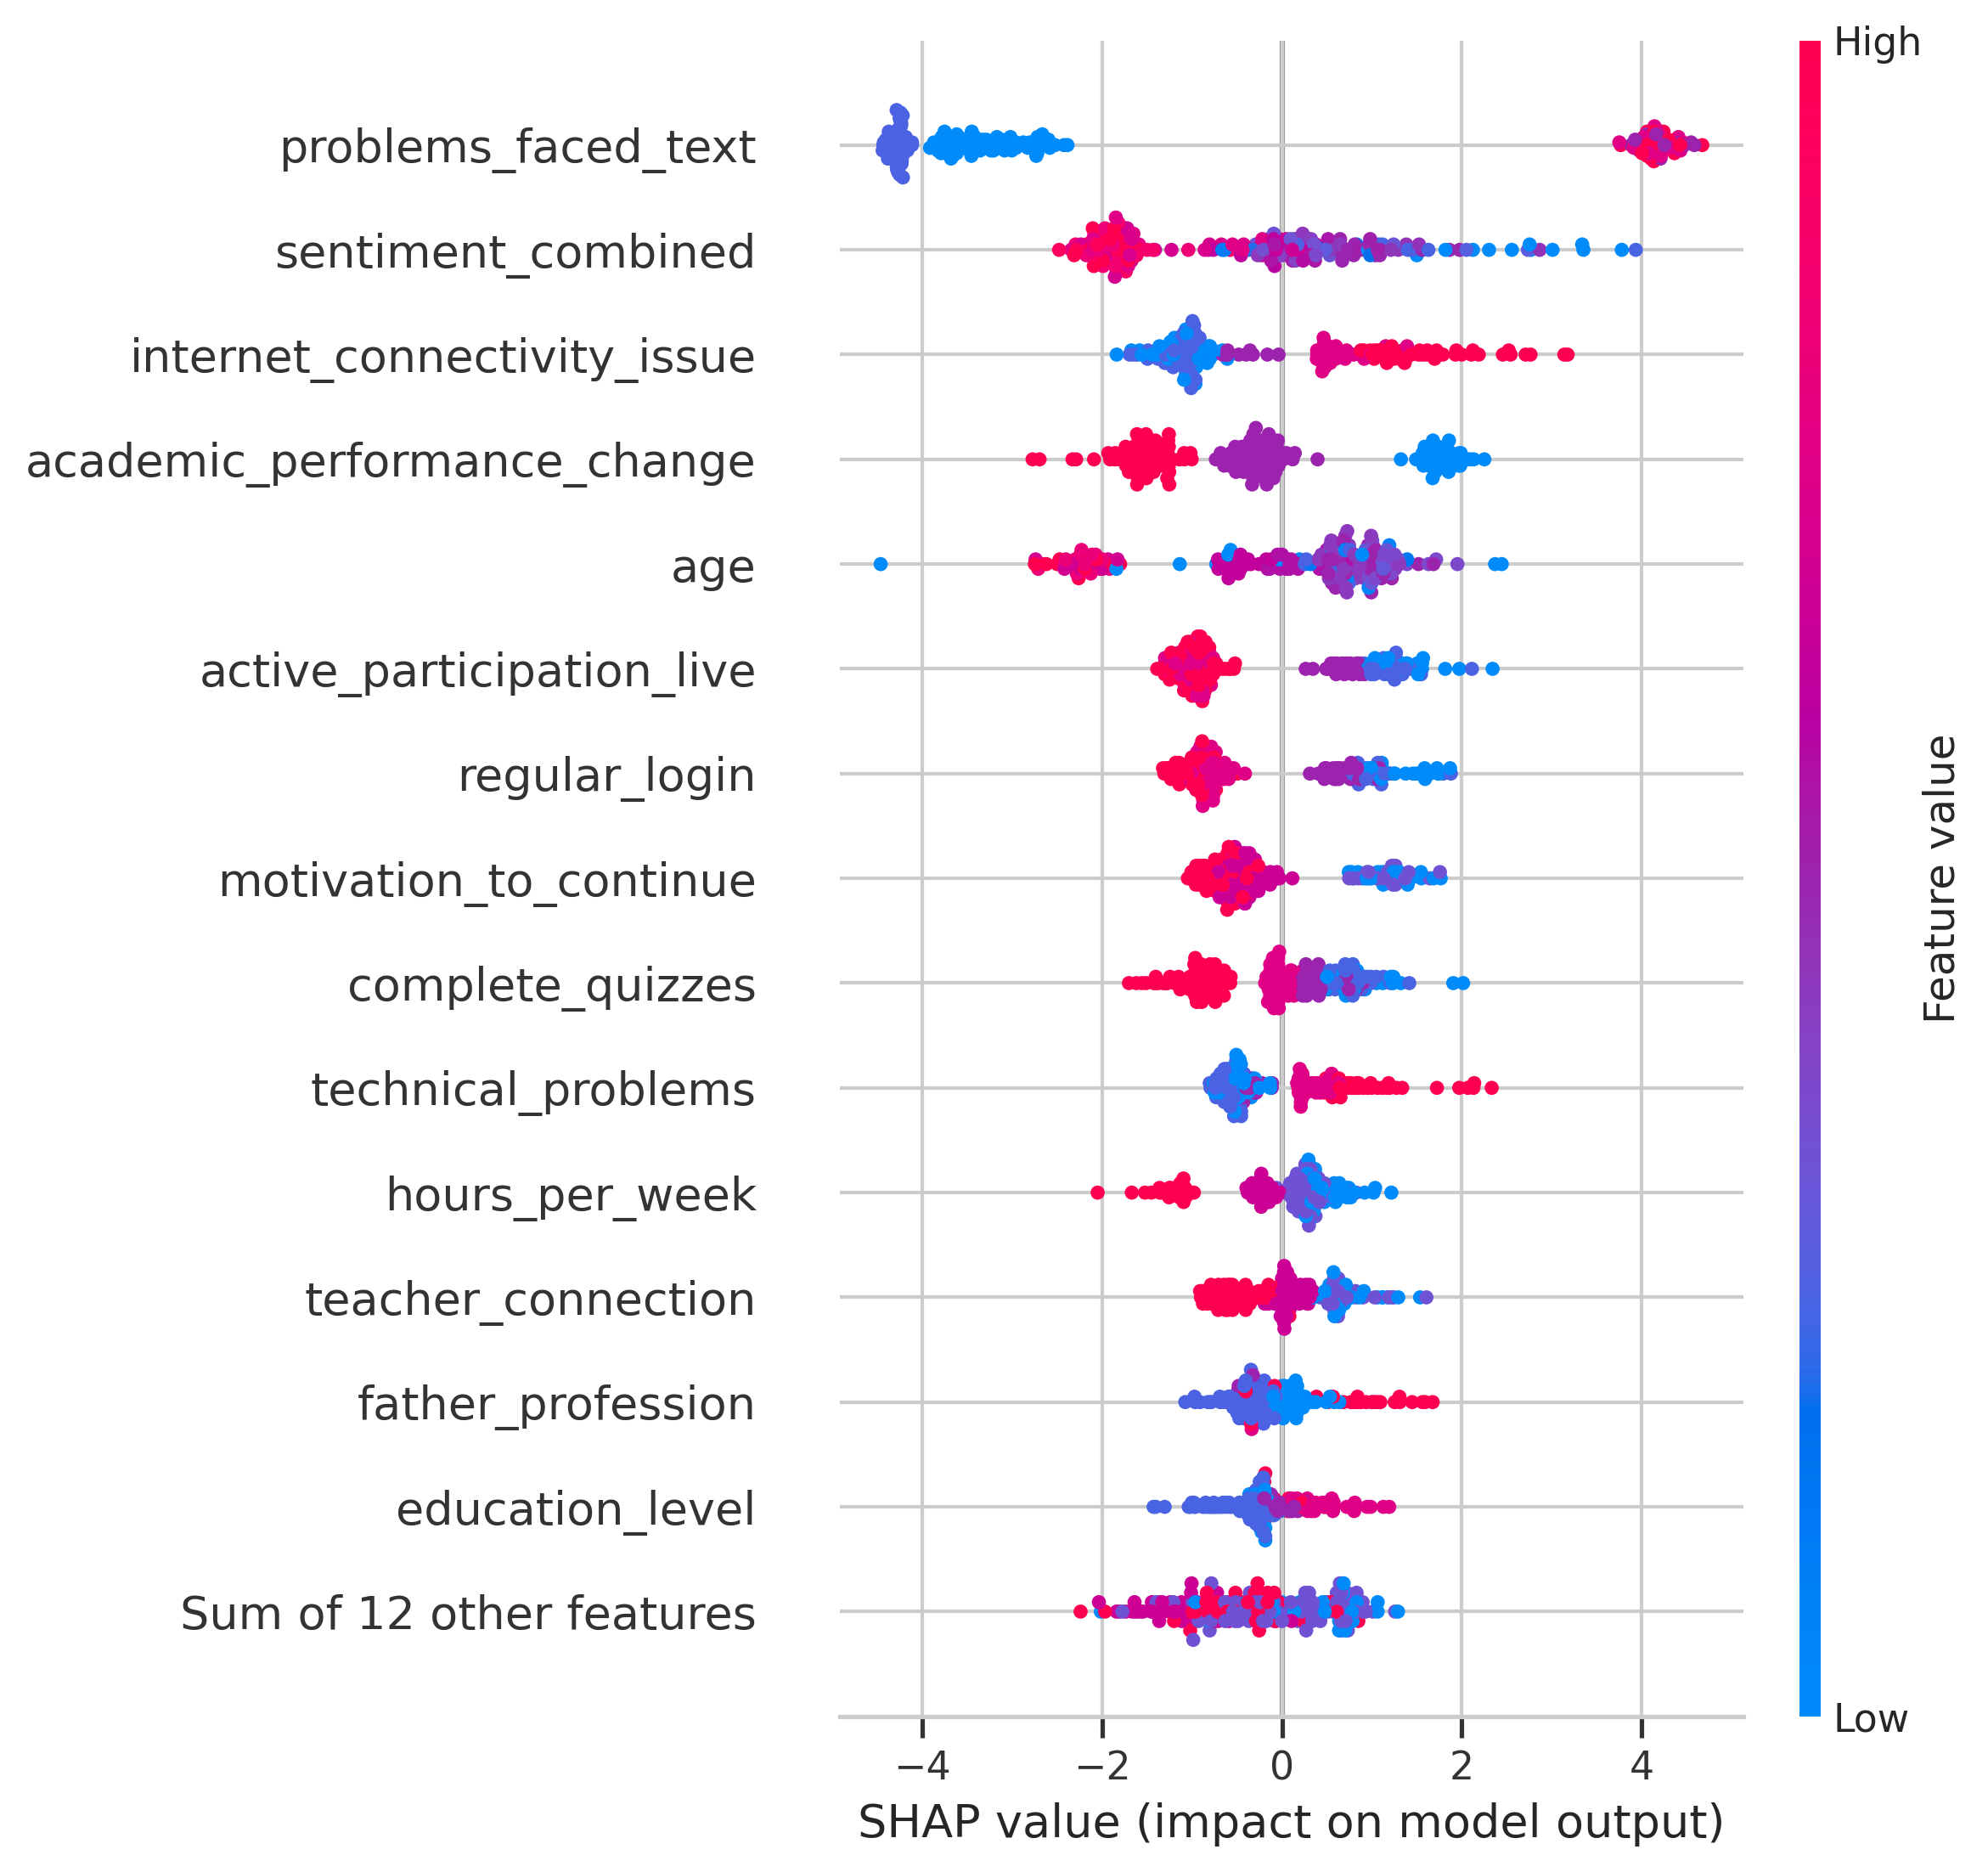

bar


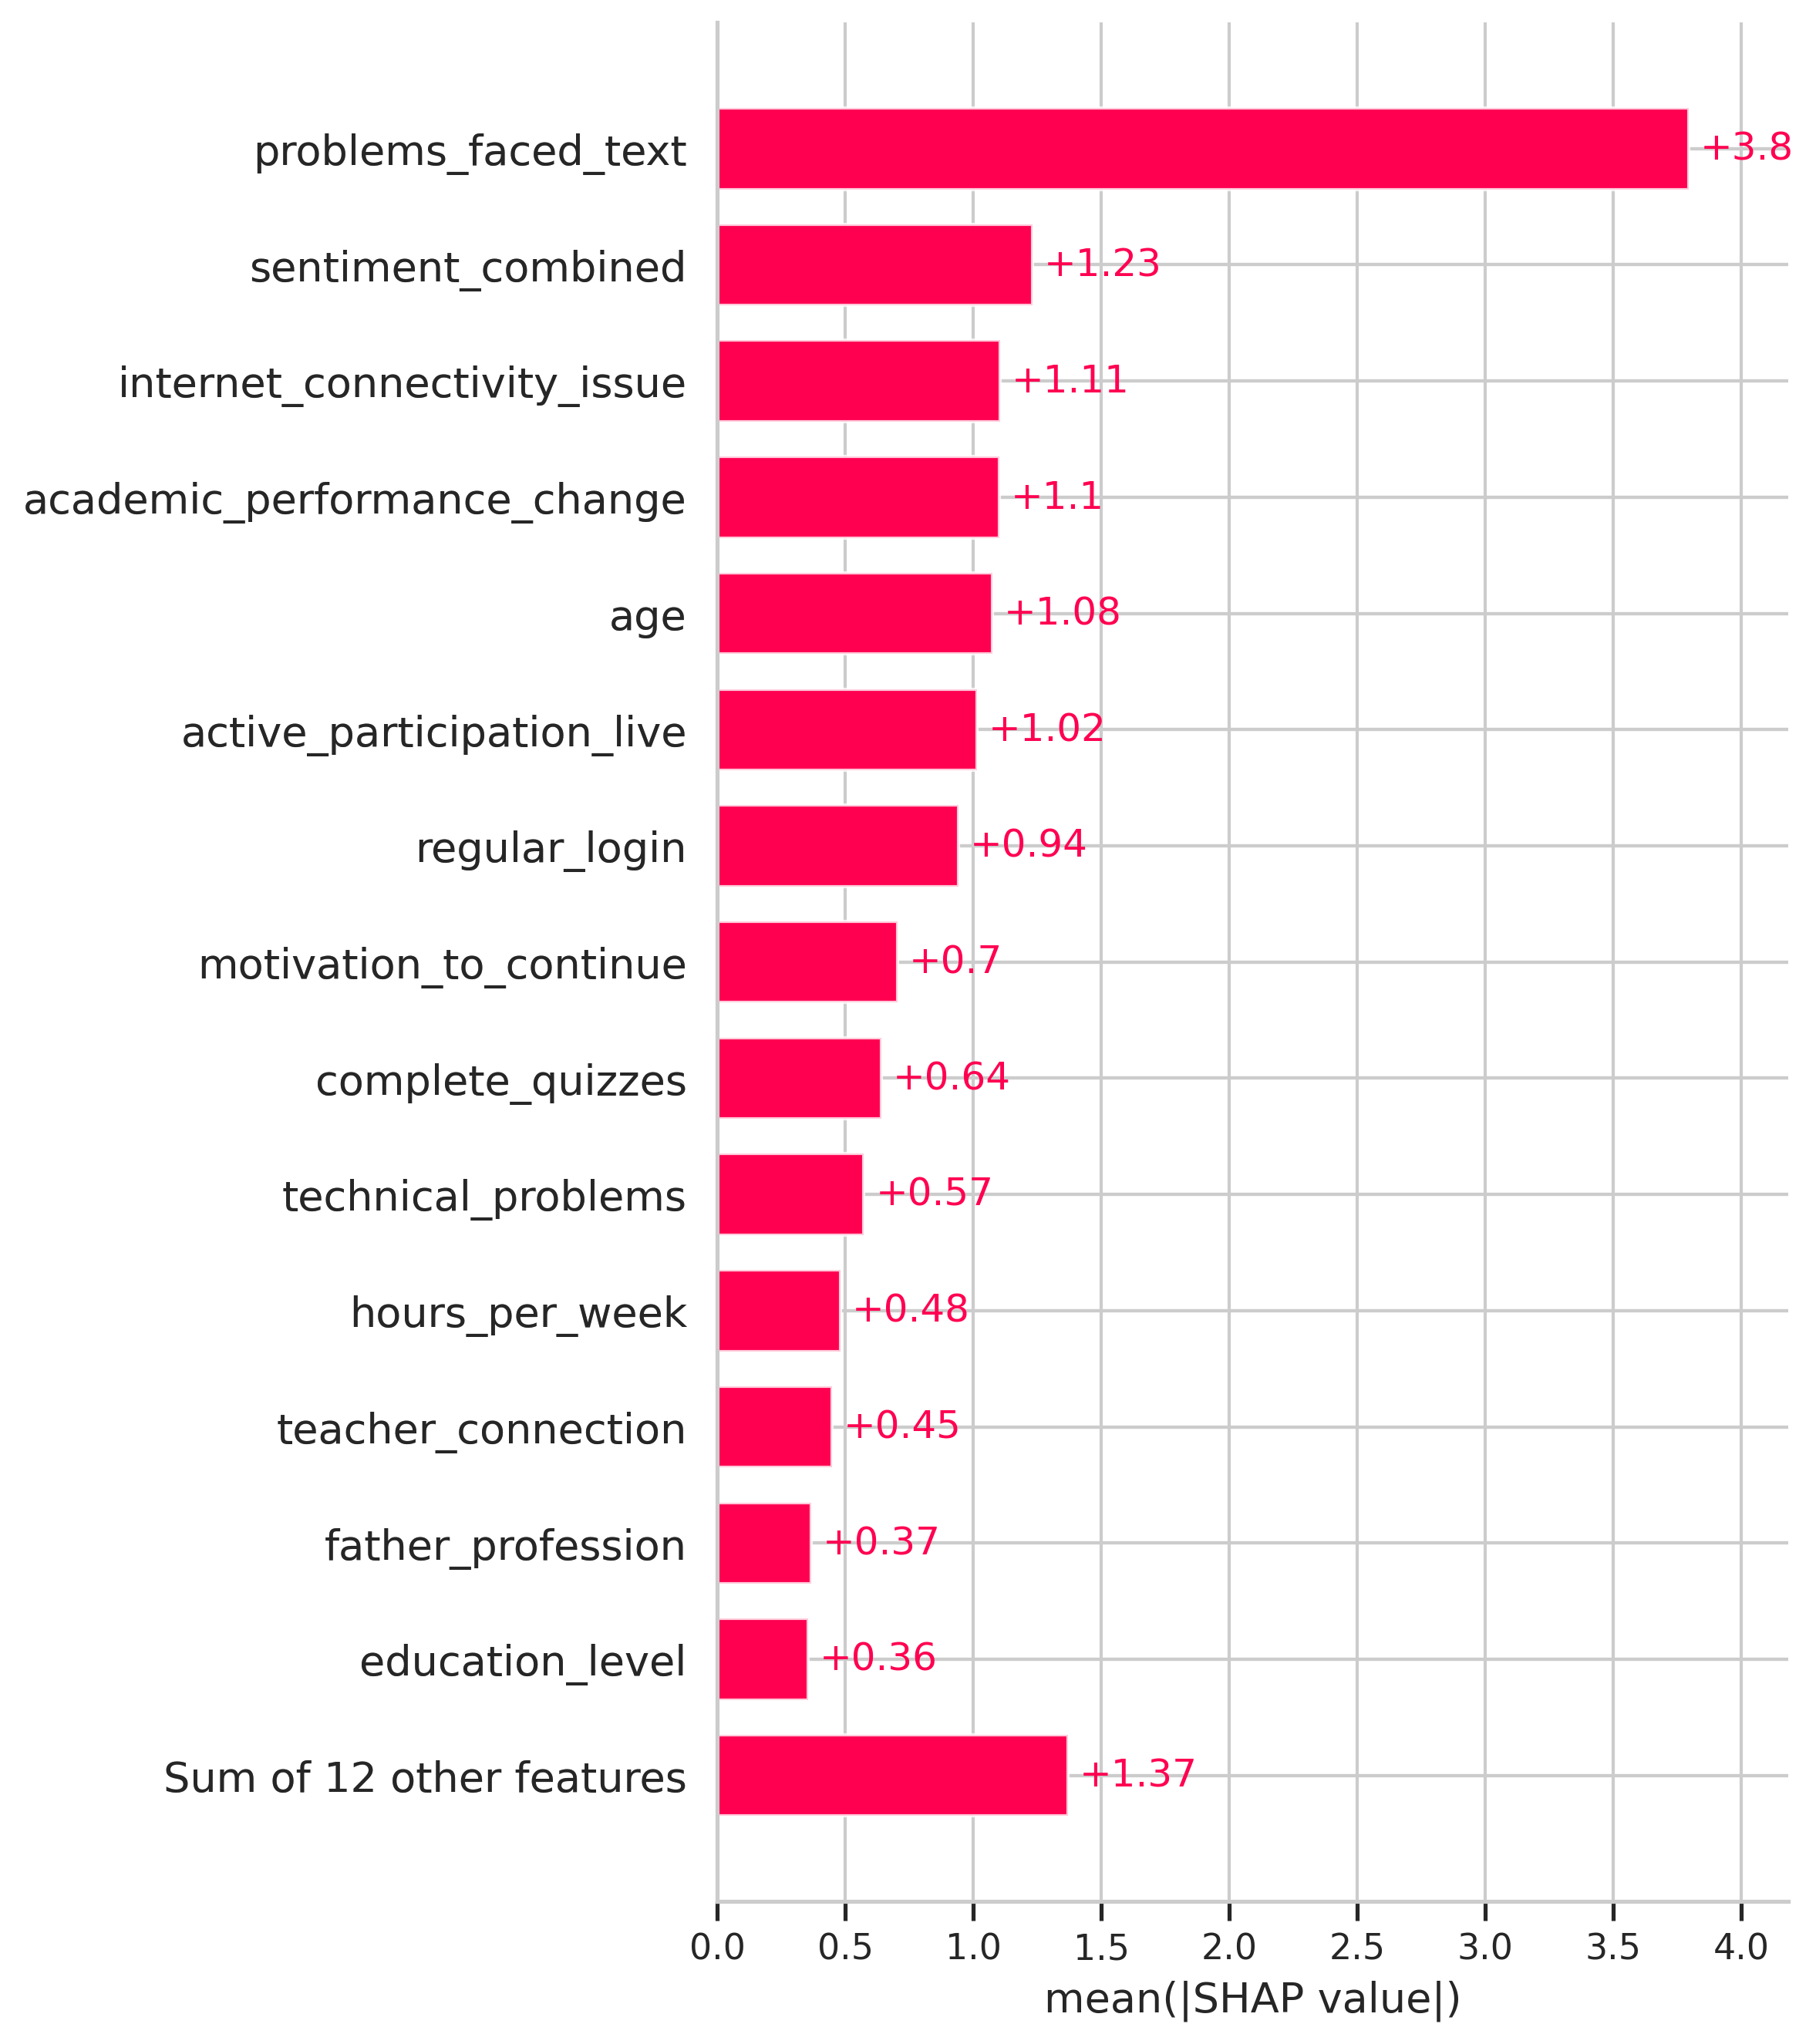

waterfall_instance0


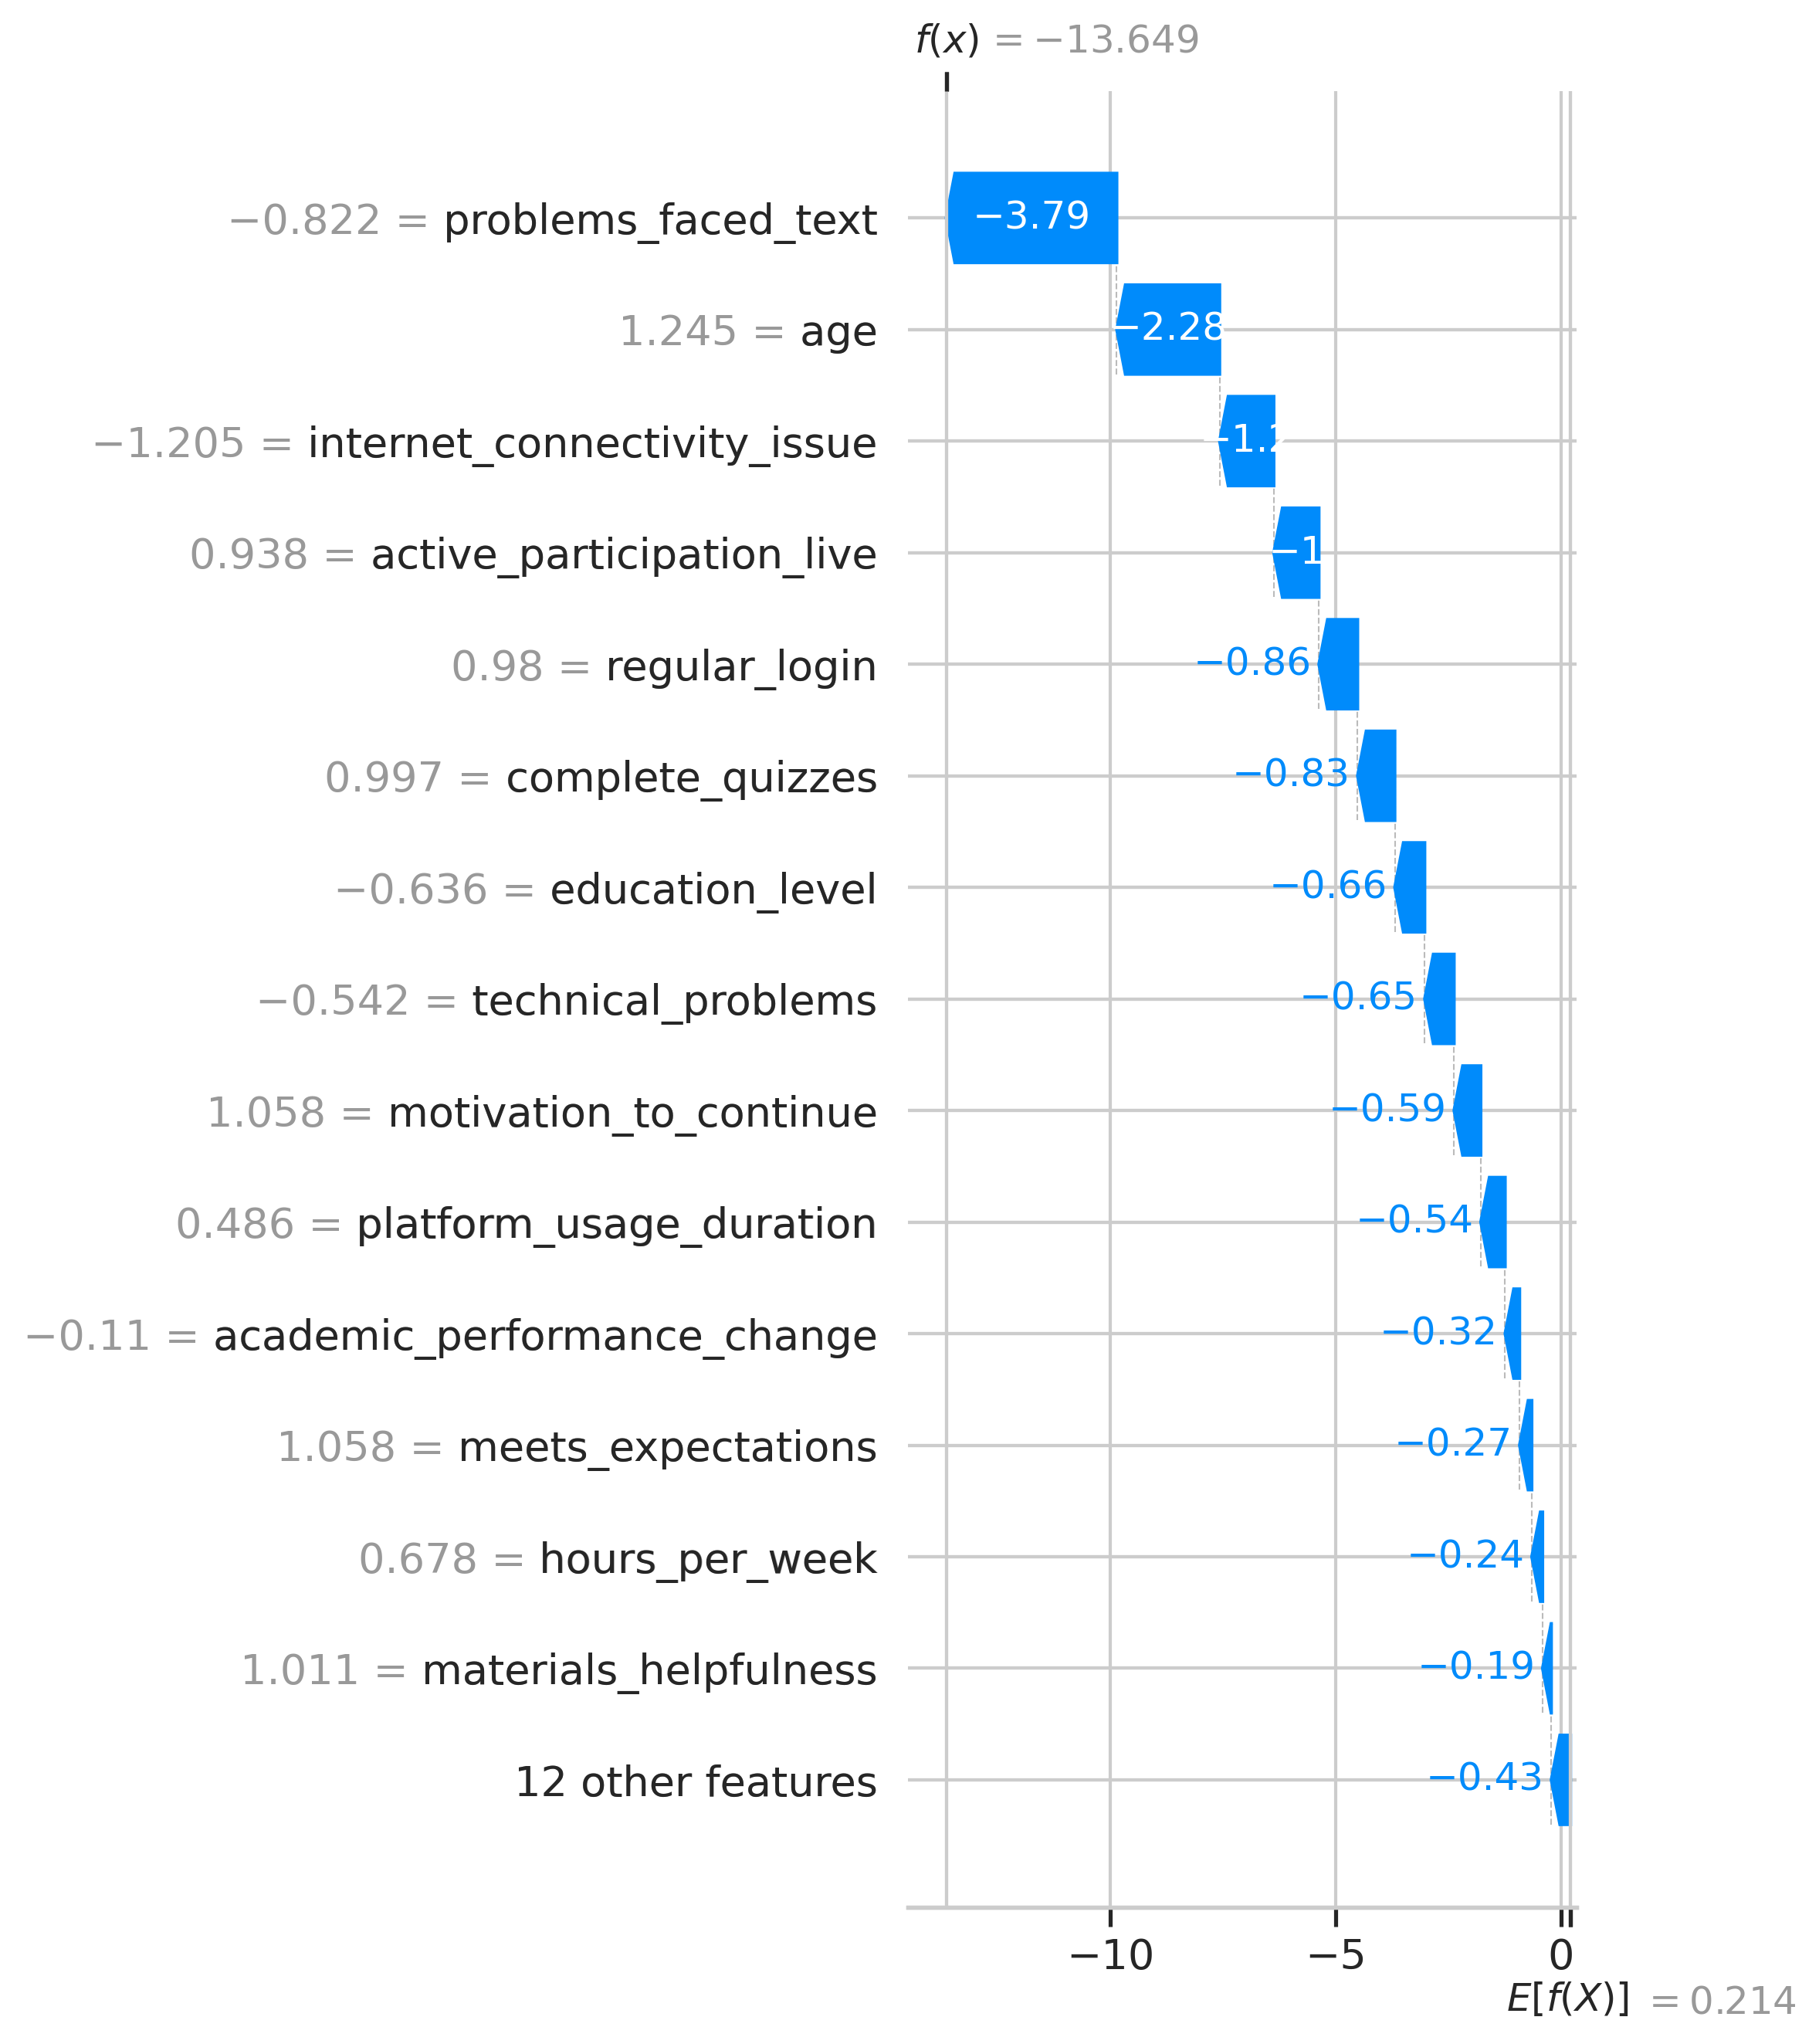

dependence_top_feature


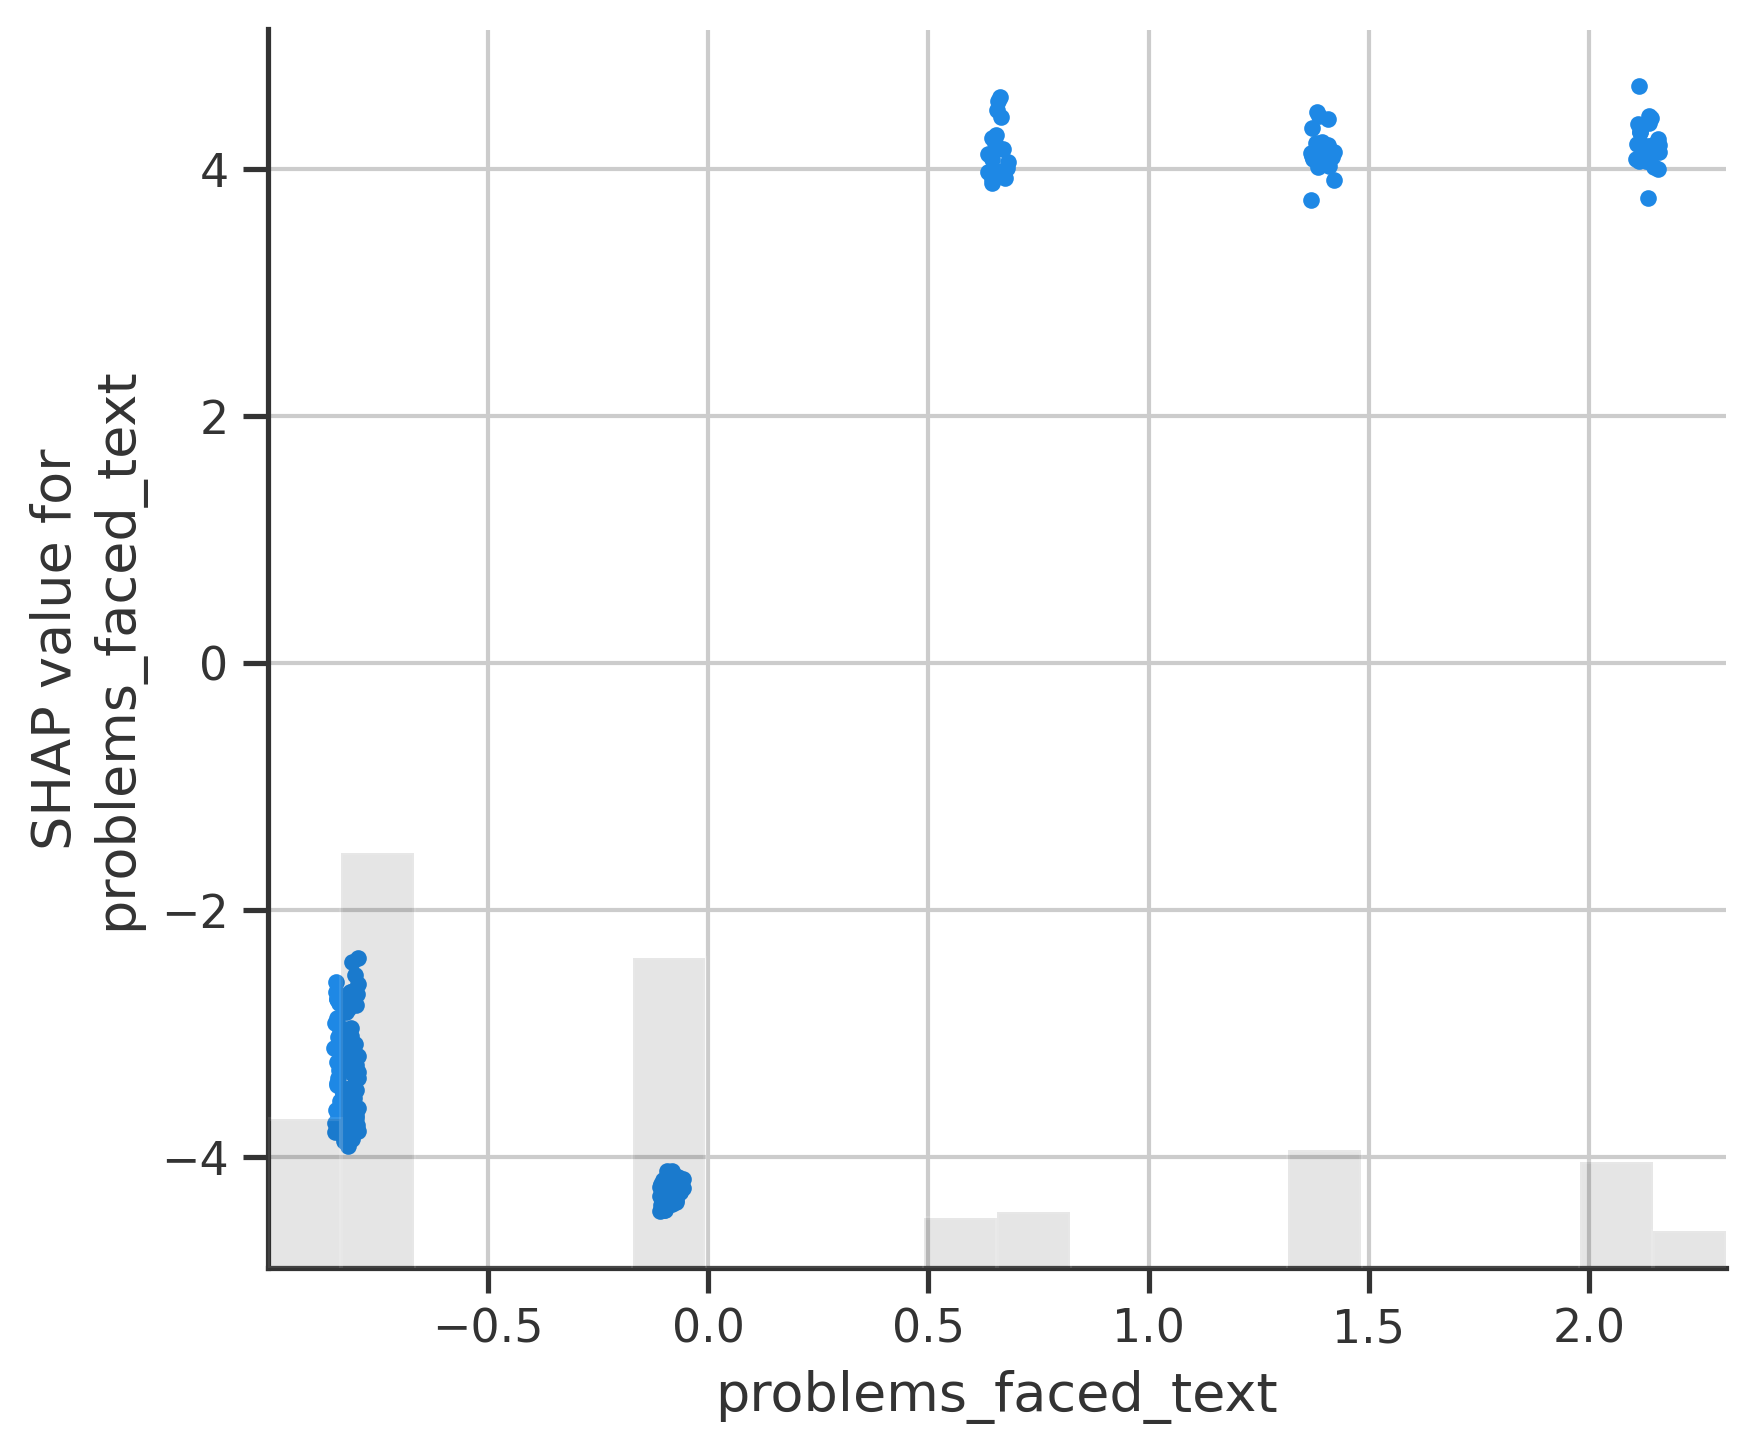


### SHAP plots — RF — TOP20_FEATURES
beeswarm


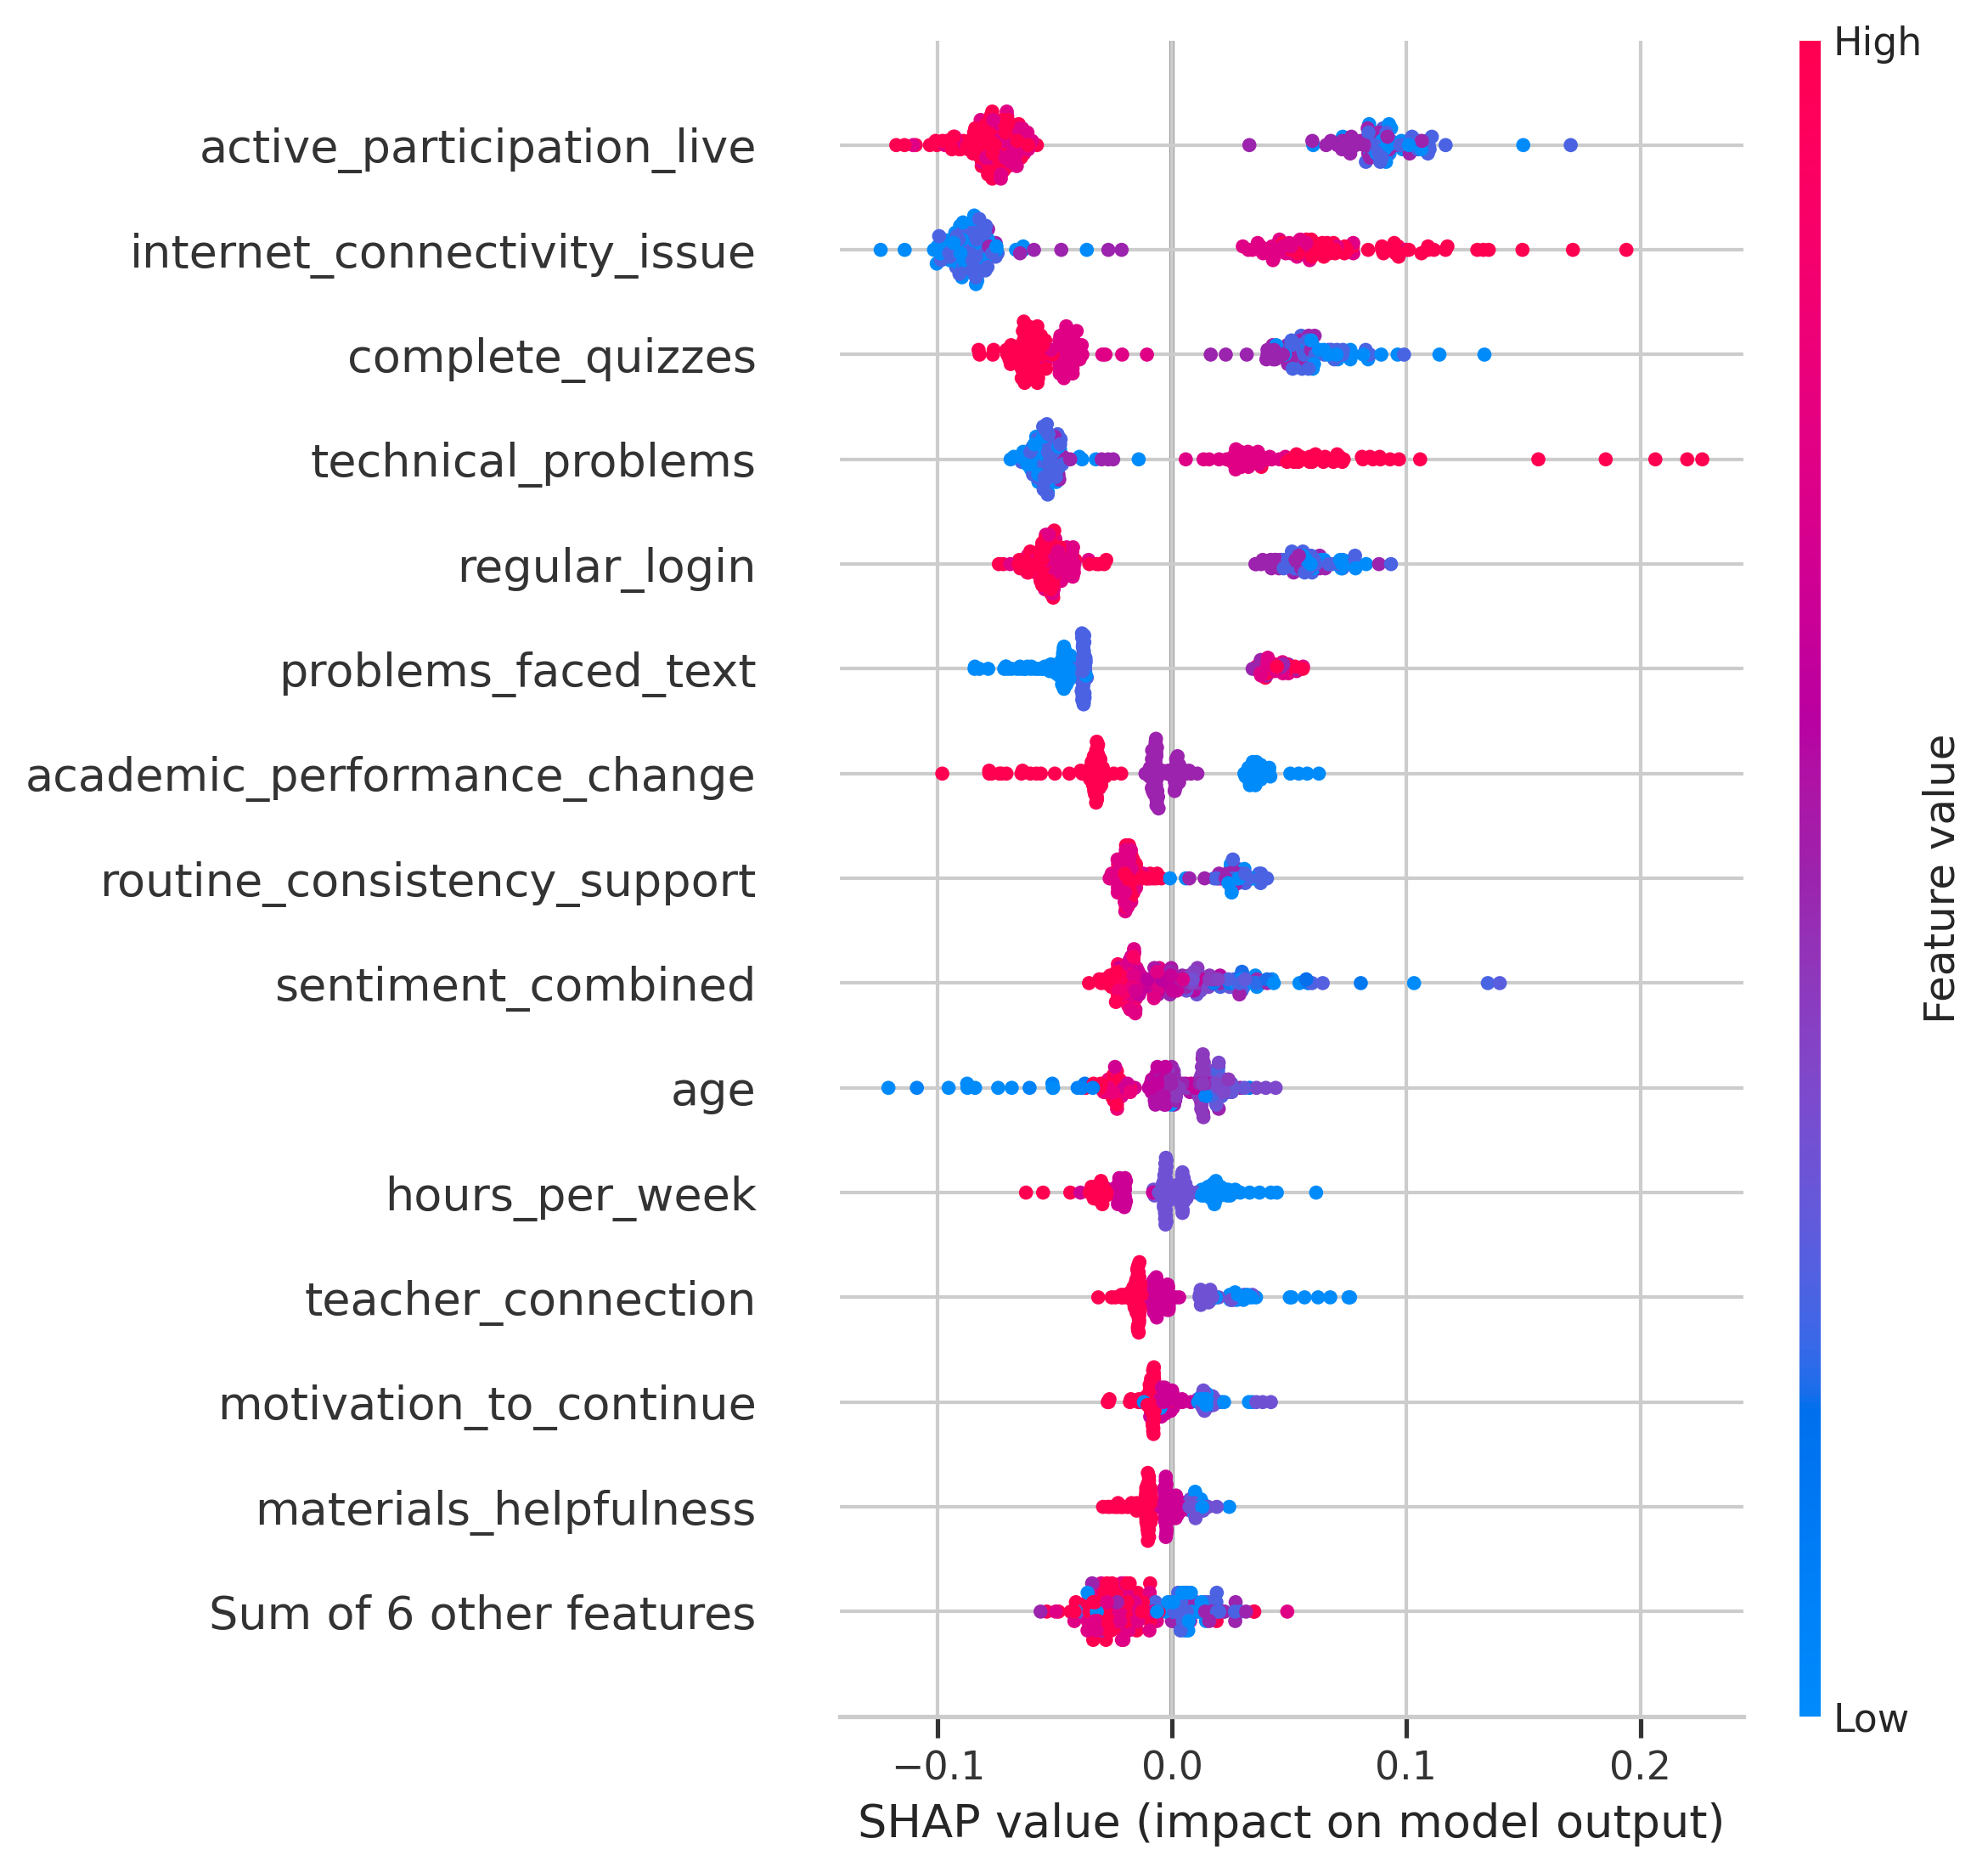

bar


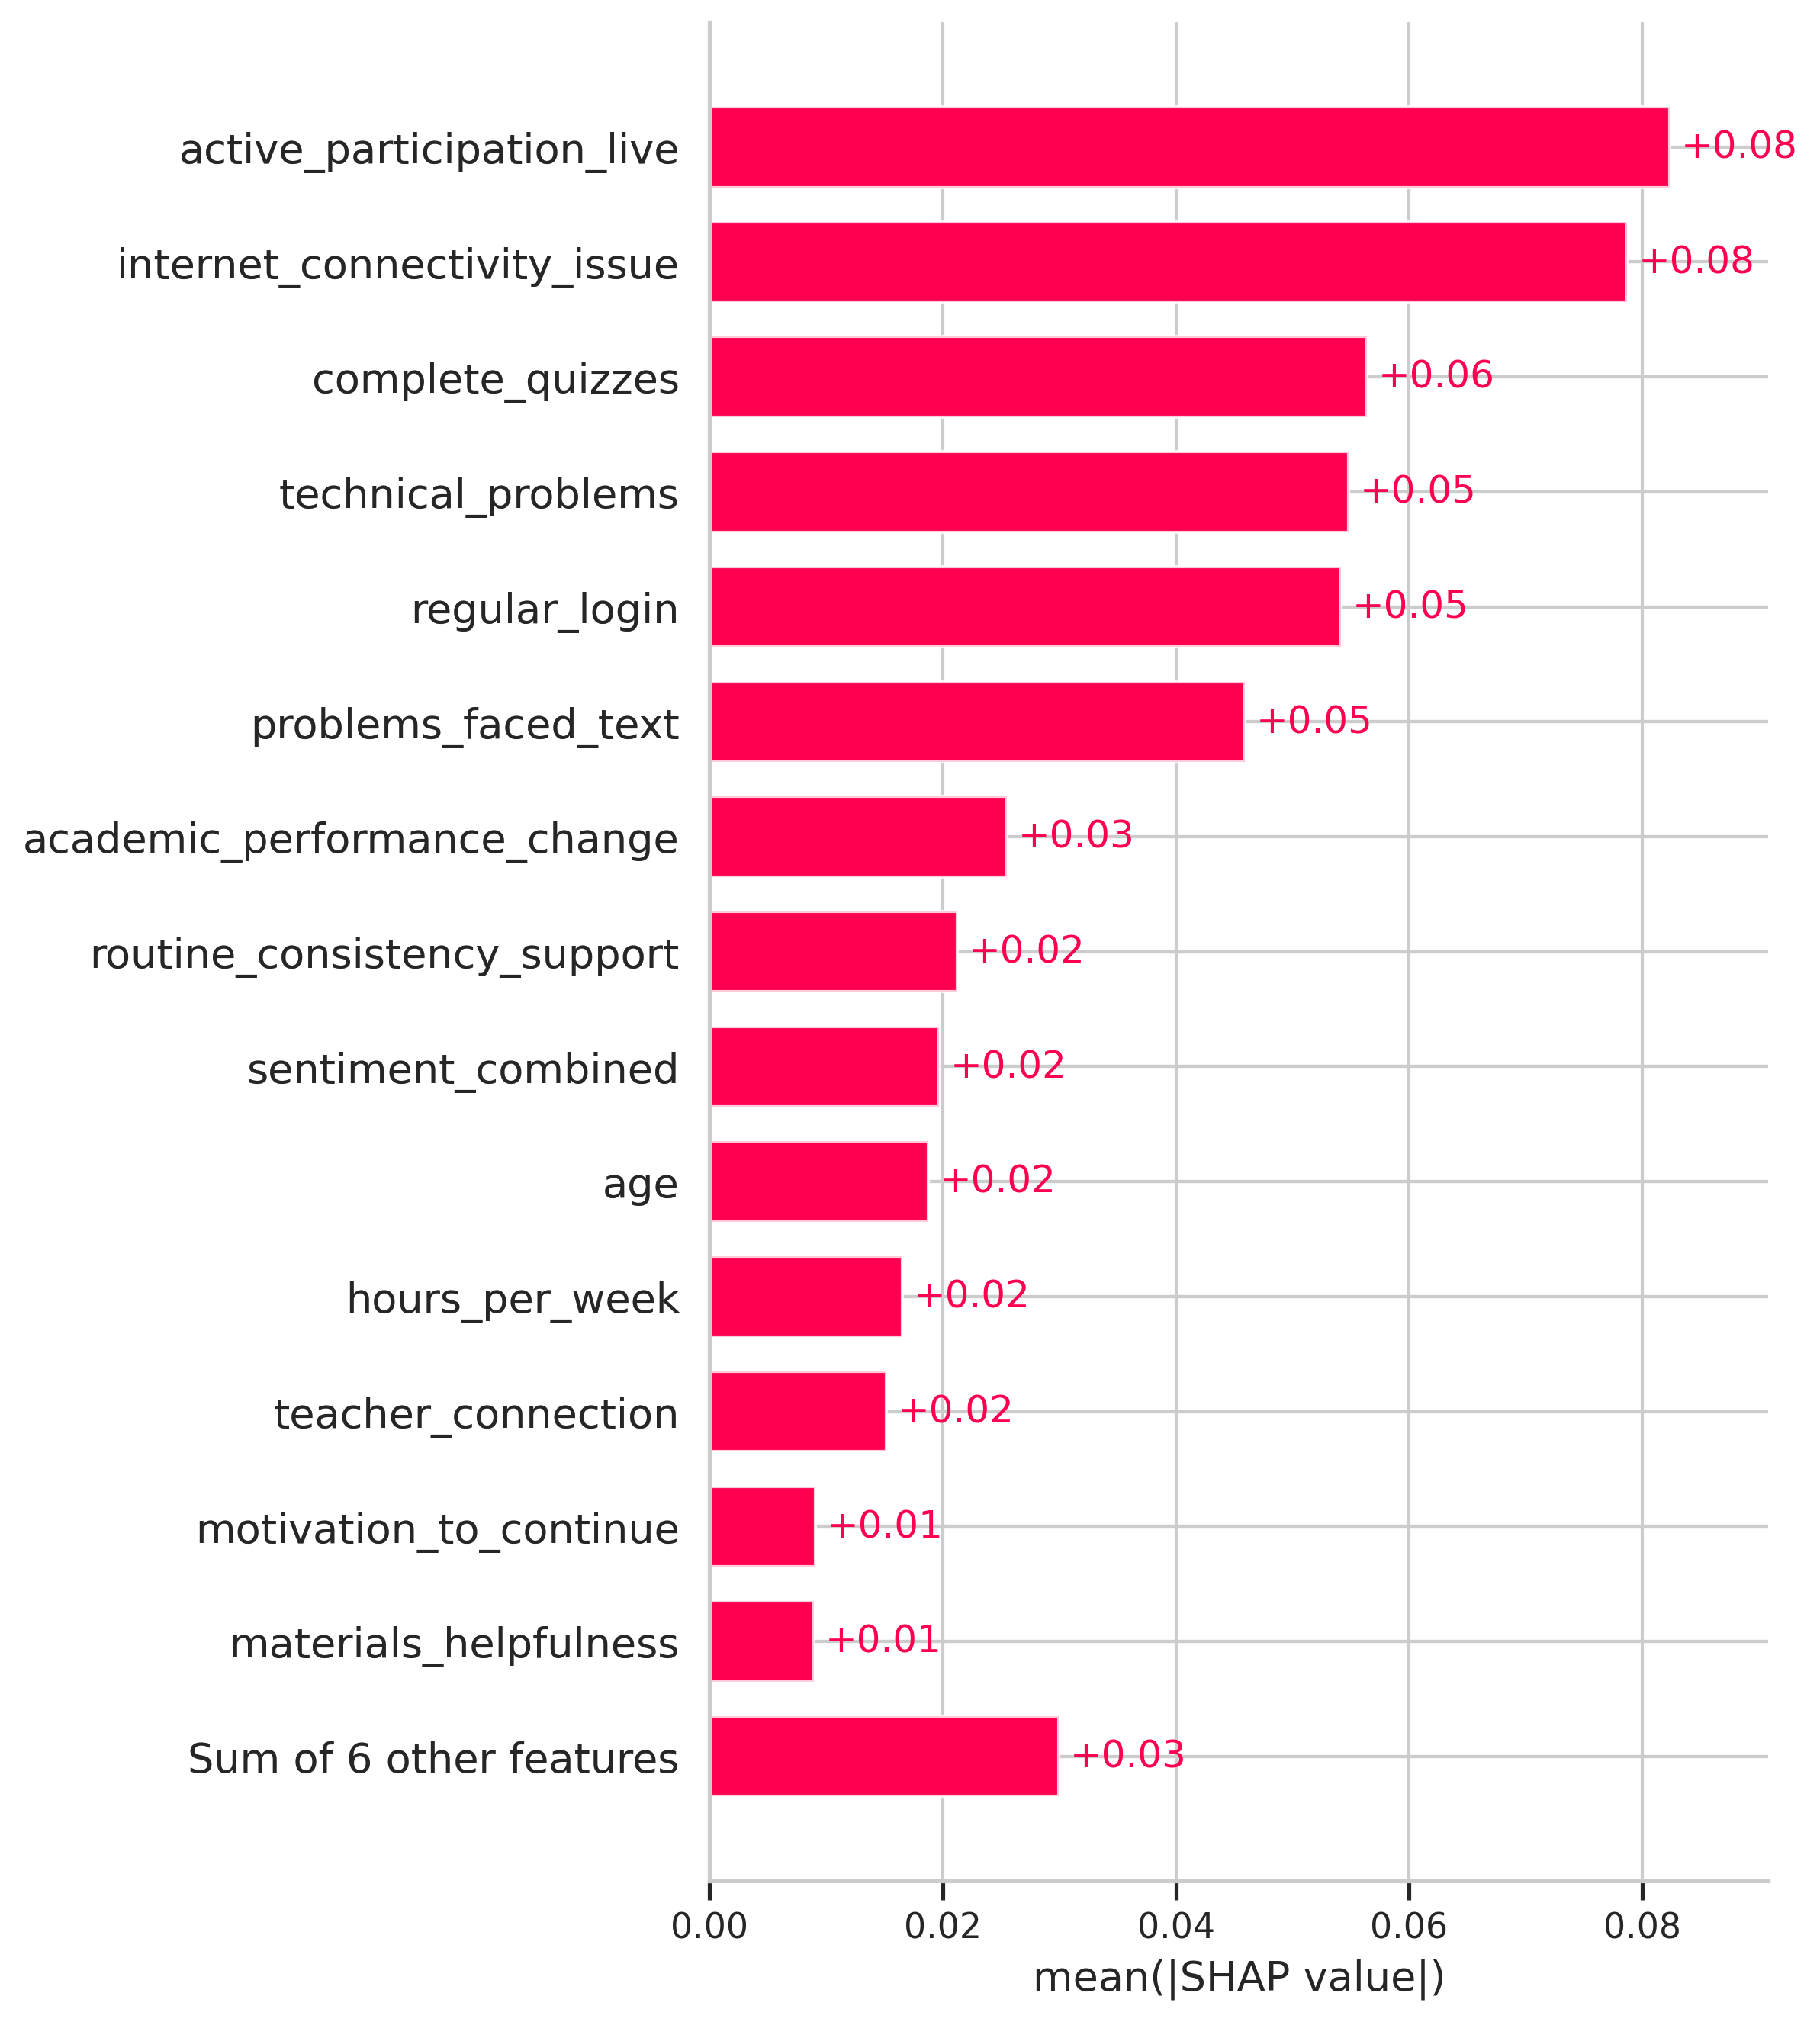

waterfall_instance0


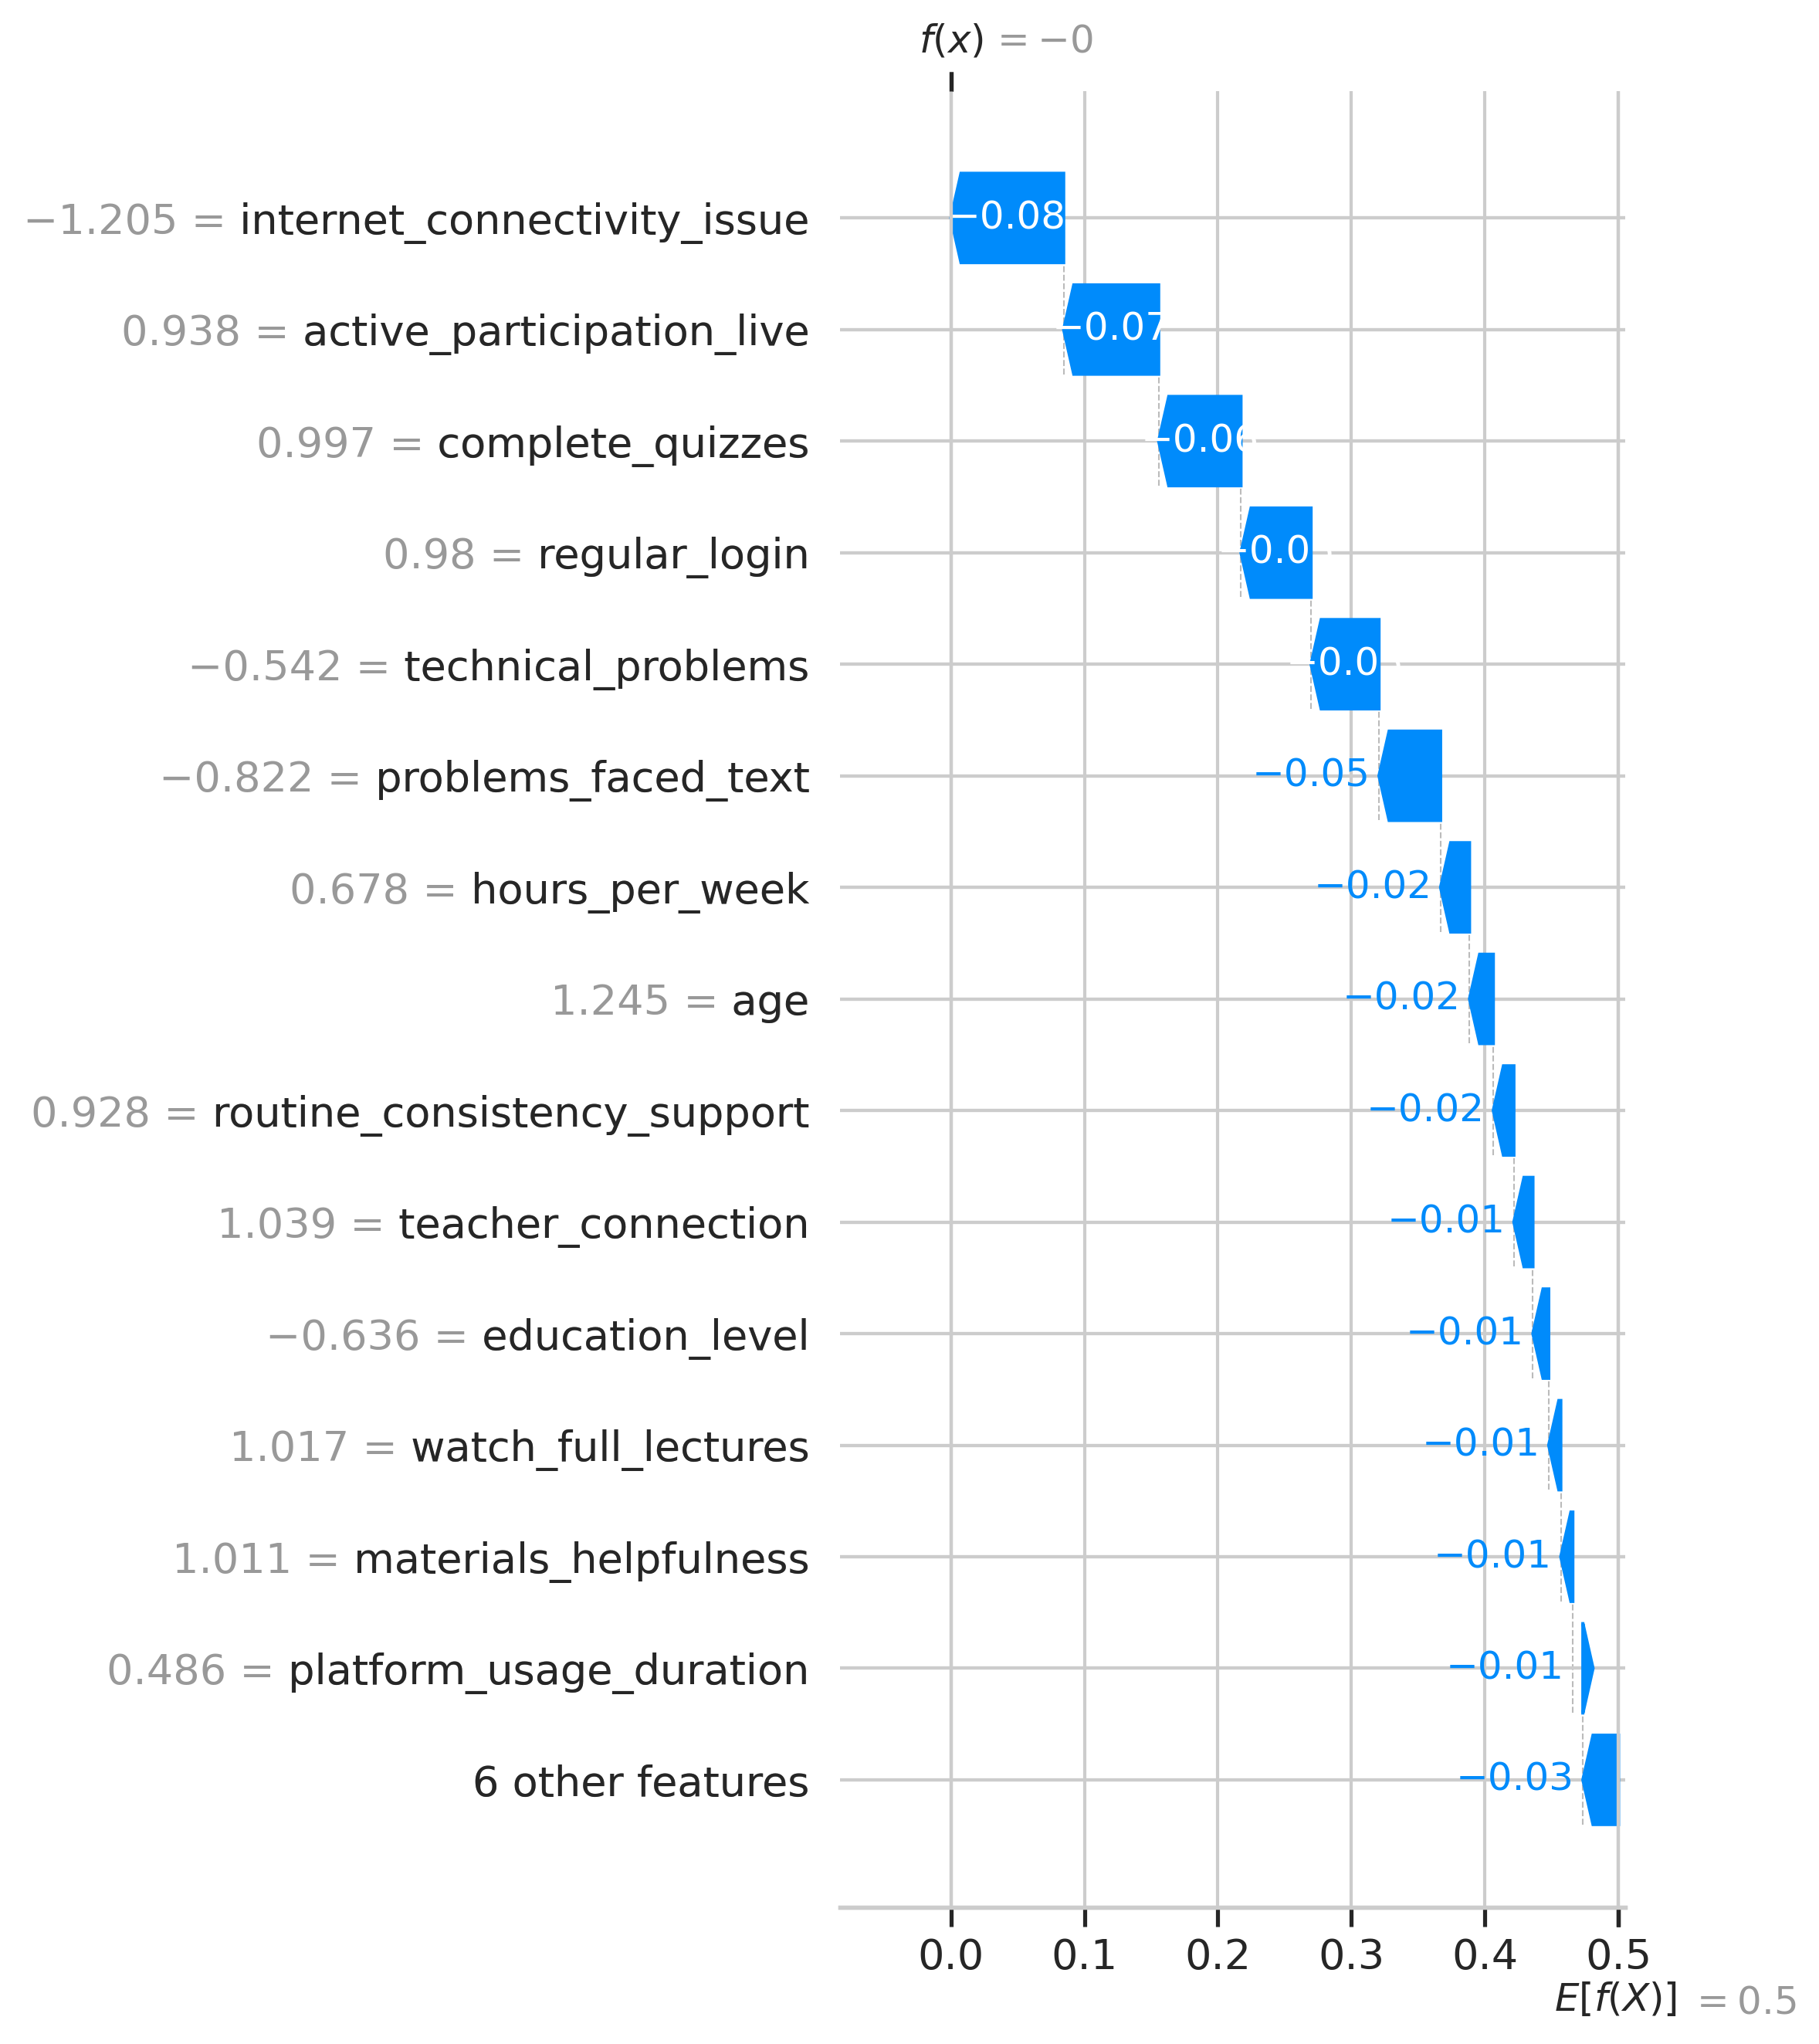

dependence_top_feature


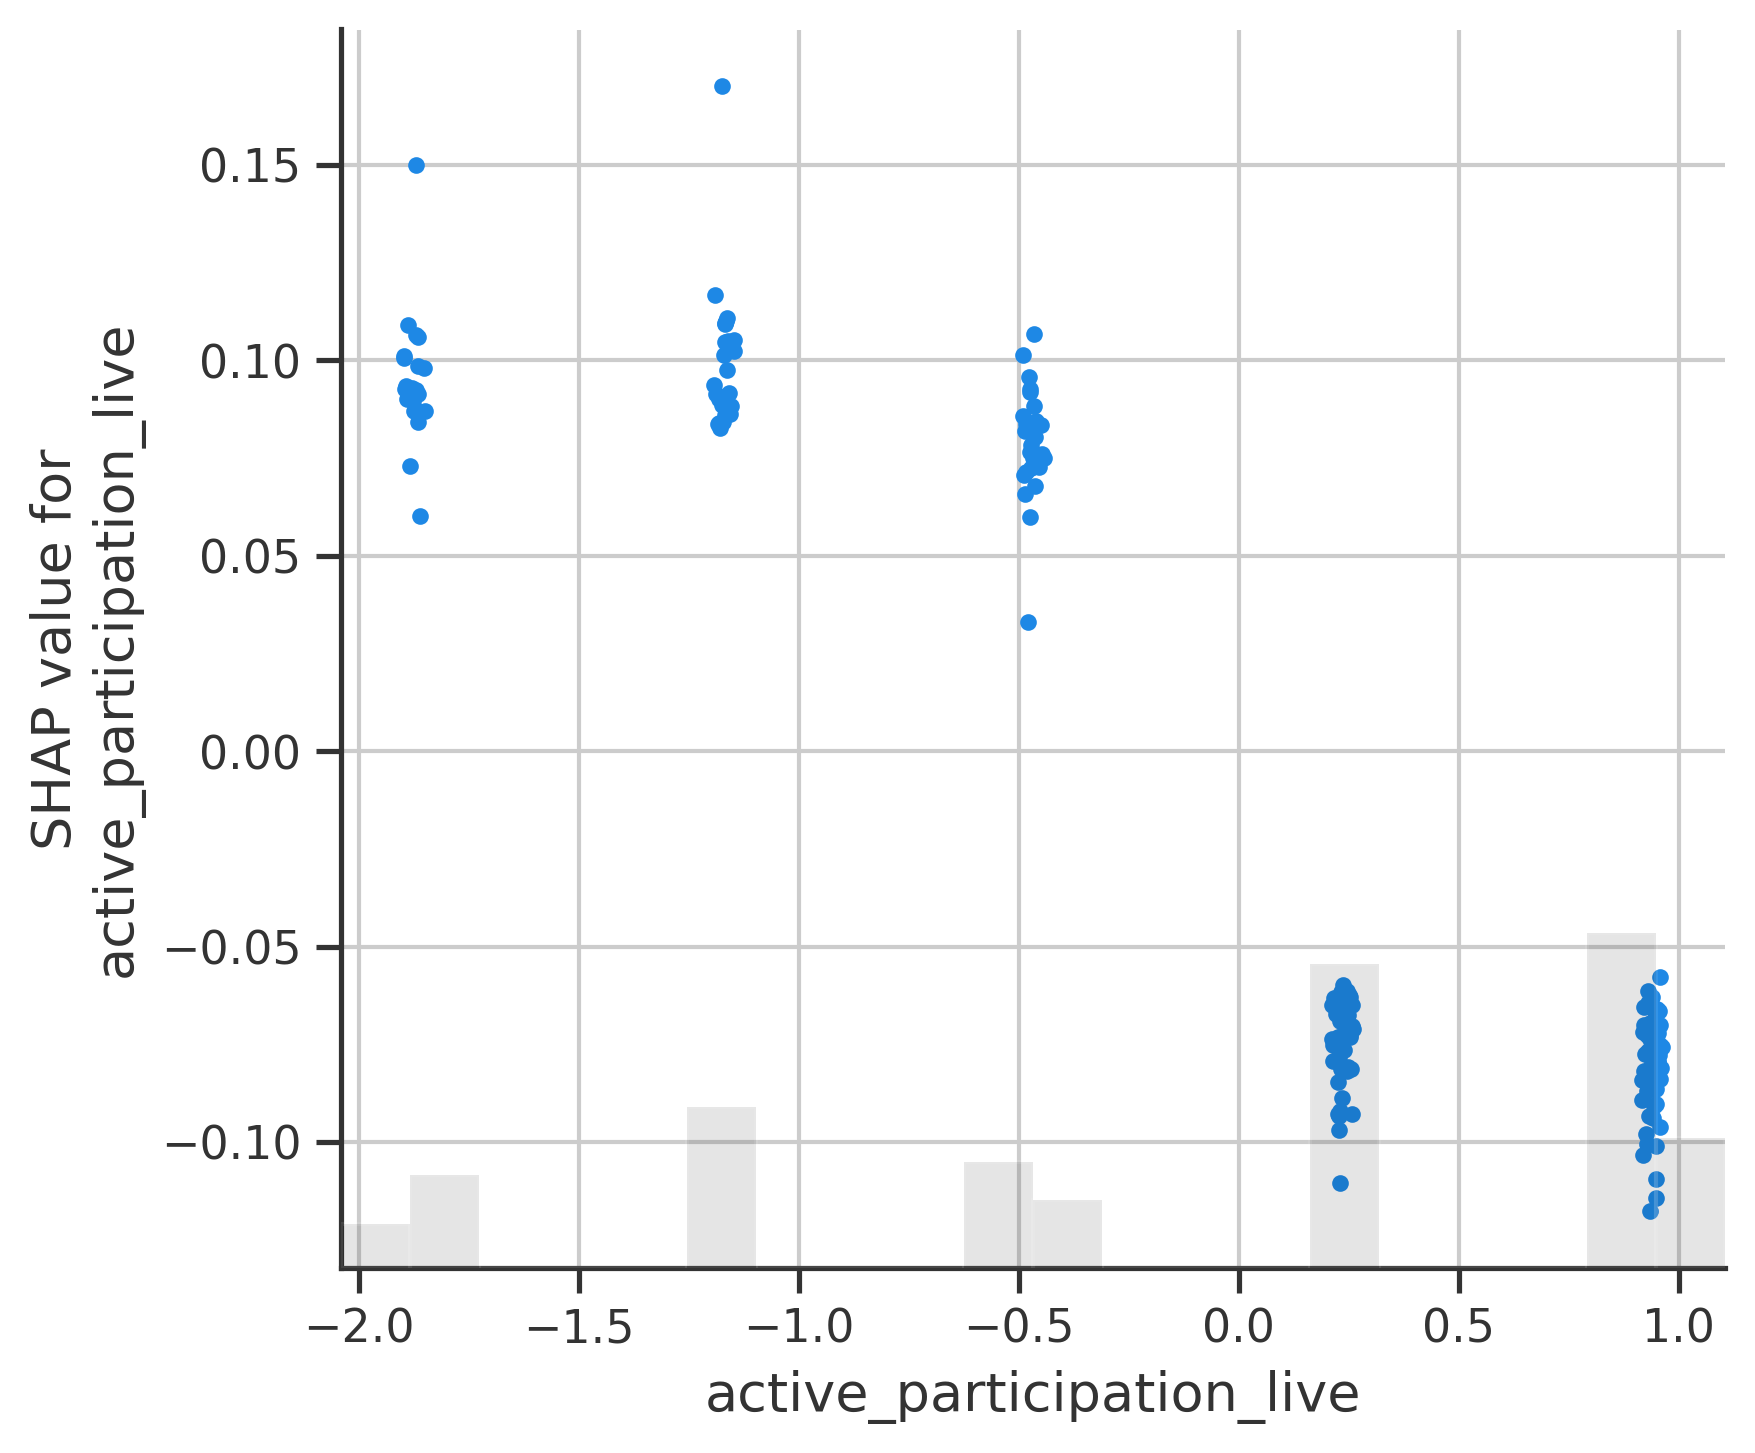

<Figure size 768x576 with 0 Axes>

<Figure size 768x576 with 0 Axes>

In [ ]:
import shap
from IPython.display import Image, display

SHAP_DIR = BASE/"10_shap"
SHAP_TREE_MODELS = ["RF", "XGBoost", "LGBM", "GradientBoosting"]     # AdaBoost is not supported by TreeExplainer

def run_tree_shap(scenario, model_name, X_explain):
    model = fitted_models.get((scenario, model_name))
    if model is None:
        return
    try:
        explainer = shap.TreeExplainer(model)
        sample = X_explain.sample(200, random_state=RANDOM_STATE) if len(X_explain) > 200 else X_explain.copy()
        sv = explainer(sample)
        if sv.values.ndim == 3:                    # some models return one slab per class -> keep dropout class
            sv = sv[:, :, 1]

        plt.figure(); shap.plots.beeswarm(sv, max_display=15, show=False); plt.tight_layout()
        plt.savefig(SHAP_DIR/f"{scenario}_{model_name}_beeswarm.png", dpi=300, bbox_inches="tight"); plt.close()

        plt.figure(); shap.plots.bar(sv, max_display=15, show=False); plt.tight_layout()
        plt.savefig(SHAP_DIR/f"{scenario}_{model_name}_bar.png", dpi=300, bbox_inches="tight"); plt.close()

        plt.figure(); shap.plots.waterfall(sv[0], max_display=15, show=False); plt.tight_layout()
        plt.savefig(SHAP_DIR/f"{scenario}_{model_name}_waterfall_instance0.png", dpi=300, bbox_inches="tight"); plt.close()

        importance = np.abs(sv.values).mean(axis=0)
        best_idx = int(np.argmax(importance))
        plt.figure(); shap.plots.scatter(sv[:, best_idx], show=False); plt.tight_layout()
        plt.savefig(SHAP_DIR/f"{scenario}_{model_name}_dependence_top_feature.png", dpi=300, bbox_inches="tight"); plt.close()

        pd.DataFrame({"feature": sample.columns, "mean_abs_shap": importance})\
          .sort_values("mean_abs_shap", ascending=False)\
          .to_csv(SHAP_DIR/f"{scenario}_{model_name}_importance.csv", index=False)
        print("SHAP completed:", scenario, model_name)
    except Exception as e:
        print("SHAP failed:", scenario, model_name, "|", repr(e))

shap_choice = {}
for scenario, _, Xte_use in SCENARIOS:
    subset = results_df[(results_df.scenario == scenario) & (results_df.model.isin(SHAP_TREE_MODELS))]\
                .sort_values(["cv_f1_mean", "cv_roc_auc_mean"], ascending=False)
    if not subset.empty:
        shap_choice[scenario] = subset.iloc[0]["model"]
        run_tree_shap(scenario, shap_choice[scenario], Xte_use)

for scenario, model_name in shap_choice.items():
    print(f"\n### SHAP plots — {model_name} — {scenario}")
    for kind in ["beeswarm", "bar", "waterfall_instance0", "dependence_top_feature"]:
        p = SHAP_DIR/f"{scenario}_{model_name}_{kind}.png"
        if p.exists():
            print(kind); display(Image(filename=str(p)))

**Interpretation output.** The retained results select LightGBM for the all-features scenario and Random Forest for the top-20 scenario. Review global rankings together with the local waterfall explanation; do not treat a high SHAP value as evidence that changing a feature will cause a learner to remain enrolled. The generated plots and importance CSV files are stored under `10_shap/`.

## 16. Export fitted models, summaries, and run metadata

The final cell saves each fitted estimator, writes a consolidated model summary, records the top models by feature scenario, and exports pipeline metadata. These files provide the reviewer with a compact audit trail of the experiment configuration and generated artefacts. The output folder is local to the notebook runtime and should be archived or attached to the repository only when its contents are appropriate for public release.

In [ ]:
for (scenario, name), model in fitted_models.items():
    if name in ["ANN", "CNN"]:
        if TF_AVAILABLE:
            model.save(BASE/"12_models"/f"{scenario}_{name}.keras")
    else:
        joblib.dump(model, BASE/"12_models"/f"{scenario}_{name}.joblib")

final_summary = pd.concat([results_df.assign(ensemble_members=""), ensemble_df], ignore_index=True, sort=False)
final_summary.to_csv(BASE/"13_summary"/"FINAL_THESIS_MODEL_SUMMARY.csv", index=False)

top_by_scenario = {}
for scenario in ["ALL_FEATURES", "TOP20_FEATURES"]:
    t = results_df[results_df.scenario == scenario].sort_values(
        ["cv_f1_mean", "cv_roc_auc_mean"], ascending=False).head(5)
    top_by_scenario[scenario] = t[["model", "cv_f1_mean", "cv_roc_auc_mean", "test_f1", "test_roc_auc"]].to_dict("records")
with open(BASE/"13_summary"/"top_models_by_scenario.json", "w") as f:
    json.dump(top_by_scenario, f, indent=2)

if categorical_cols:
    preprocessing_description = (
        "numeric: median imputation + standardization; categorical: most-frequent "
        "imputation + one-hot encoding; fitted on the full training partition before CV"
    )
else:
    preprocessing_description = (
        "all active predictors are numeric after fixed ordinal/nominal coding; "
        "median imputation + standardization; one-hot branch inactive; "
        "fitted on the full training partition before CV"
    )

metadata = {
    "created": datetime.now().isoformat(),
    "random_state": RANDOM_STATE, "test_size": TEST_SIZE, "cv_folds": N_SPLITS,
    "dataset_shape": list(df_raw.shape),
    "target_distribution": y.value_counts().sort_index().to_dict(),
    "banglabert_model": "ahs95/banglabert-sentiment-analysis",
    "open_ended_questions_to_features": OPEN_ENDED_QUESTIONS,
    "n_structured_questions": N_STRUCTURED, "n_open_ended_questions": N_OPEN,
    "n_raw_features_before_encoding": int(X_raw.shape[1]),
    "n_encoded_features_all_scenario": int(Xtr.shape[1]),
    "excluded_columns": EXCLUDED_COLUMNS,
    "ordered_questions_as_single_column": ORDERED_QUESTIONS_AS_SINGLE_COLUMN,
    "merge_all_sentiment_into_one": MERGE_ALL_SENTIMENT_INTO_ONE,
    "top20_features": top20_features,
    "feature_selection": "mutual_information_on_training_data_only",
    "preprocessing": preprocessing_description,
    "nominal_questions_as_single_column": NOMINAL_QUESTIONS_AS_SINGLE_COLUMN,
    "categorical_columns_one_hot_encoded": list(categorical_cols),
    "preprocessing_fit_scope": "full 80% training partition before five-fold CV",
    "feature_selection_fit_scope": "full 80% training partition before five-fold CV",
    "smote": "fold-wise on training subsets only; final fit on training partition only",
    "ensemble_selection": "top 3 by 5-fold CV F1, then mean probability soft voting",
    "test_set_used_for_selection": False,
}
with open(BASE/"14_metadata"/"pipeline_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2, default=str)

with open(BASE/"13_summary"/"README_THESIS_RESULTS.txt", "w", encoding="utf-8") as f:
    f.write("ONLINE LEARNING DROPOUT — THESIS RESULT OUTPUTS\n" + "=" * 70 + "\n\n")
    f.write(f"Dataset shape: {df_raw.shape}\n")
    f.write(f"Questions used: {N_STRUCTURED} structured + {N_OPEN} open-ended (BanglaBERT sentiment)\n")
    f.write(f"Encoded features (all-features scenario): {Xtr.shape[1]}\n")
    f.write("5-fold stratified CV; held-out 20% test set.\n")
    f.write(f"Active encoding: ordered single-column={ORDERED_QUESTIONS_AS_SINGLE_COLUMN}; ")
    f.write(f"nominal single-column={NOMINAL_QUESTIONS_AS_SINGLE_COLUMN}; ")
    f.write(f"one-hot categorical columns={len(categorical_cols)}.\n")
    f.write("Preprocessing and MI ranking are fitted on the full training partition before CV; ")
    f.write("SMOTE is applied within each CV training fold.\n\nTop models by scenario (CV F1):\n")
    for scenario, records in top_by_scenario.items():
        f.write("\n" + scenario + "\n")
        for r in records:
            f.write(str(r) + "\n")

print("PIPELINE COMPLETE  ->", BASE.resolve())

**Files produced.** The main artefacts are:

- `05_cv_results/` — fold-level and consolidated model metrics.
- `07_confusion_matrices/`, `08_roc_curves/`, and `09_pr_curves/` — held-out diagnostic figures.
- `10_shap/` — SHAP plots and feature-importance exports.
- `11_ensembles/` — ensemble predictions and metrics.
- `12_models/` — fitted estimators and the preprocessing object.
- `13_summary/` and `14_metadata/` — final comparison tables, top-model summaries, and configuration metadata.

The original Google Drive auto-mount/copy convenience cell has been omitted from this review version so that running the notebook does not trigger account authorization or write to a personal Drive location. The analytical pipeline and model settings remain unchanged.